<div align="center">

# Facultad de Ciencias Exactas, Ingeniería y Agrimensura
## Universidad Nacional de Rosario (UNR)

---

# Aprendizaje Automático 1
## Trabajo Práctico: Predicción de lluvia en Australia

**Integrantes:** _Cortinas Bautista, Cura Valentin, Maragliano Franco_

---
</div>

## Contenidos

0. Preparación: librerías y carga de datos
1. **Ítem 1 – Análisis descriptivo**
   - 1.1 Diccionario de variables
   - 1.2 Revisión de integridad: duplicados y valores imposibles
   - 1.3 Fuga de datos y limpieza inicial
   - 1.4 Diagnóstico y decisión sobre datos faltantes
   - 1.5 División en entrenamiento, validación y prueba
   - 1.6 Balance de clases
   - 1.7 Distribuciones, valores extremos y visualizaciones
   - 1.8 Ingeniería y codificación de variables
   - 1.9 Matriz de correlación
   - 1.10 Imputación, codificación y estandarización
2. **Ítem 2 – Regresión logística**
   - 2.1 Métricas y protocolo de evaluación
   - 2.2 Entrenamiento y matrices de confusión
   - 2.3 Curvas ROC
   - 2.4 Elección del umbral
   - 2.5 Evaluación final en el conjunto de prueba
   - 2.6 Análisis del fitting
3. **Ítem 3 – Modelos base**

## 0. Preparación

Se usan pandas y NumPy para manipular los datos, matplotlib y seaborn para los gráficos y
scikit-learn para el preprocesamiento, los modelos y las métricas. `RANDOM_STATE` fija la
semilla de todo lo que tiene un componente aleatorio, para que los resultados se puedan
reproducir.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, average_precision_score,
    balanced_accuracy_score, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score, roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

RANDOM_STATE = 42

El CSV se busca primero junto al notebook (repositorio clonado), después en la carpeta de
ejemplo de Colab y, si no está en ninguno de los dos lugares, se lee desde el repositorio
de GitHub. El archivo original nunca se modifica: todas las transformaciones se hacen
sobre la copia cargada en memoria.

In [2]:
RUTAS_CSV = [
    "weatherAUS_2026C2.csv",
    "/content/sample_data/weatherAUS_2026C2.csv",
    "https://raw.githubusercontent.com/FrancoM02/TP_AA1_Maragliano_Cura_Cortinas/main/TP_2/weatherAUS_2026C2.csv",
]
RUTA_CSV = next(r for r in RUTAS_CSV if r.startswith("http") or os.path.exists(r))

data = pd.read_csv(RUTA_CSV)
print(f"Leído desde: {RUTA_CSV}")
print(f"Filas: {data.shape[0]}   Columnas: {data.shape[1]}")

Leído desde: weatherAUS_2026C2.csv
Filas: 145412   Columnas: 25


`info()` muestra el tipo de dato y la cantidad de valores no nulos de cada columna, y
`head()` las primeras filas, para ver el formato de cada variable.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 145412 entries, 0 to 145411
Data columns (total 25 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        145412 non-null  int64  
 1   Date              145412 non-null  str    
 2   Location          145412 non-null  str    
 3   MinTemp           143928 non-null  float64
 4   MaxTemp           144159 non-null  float64
 5   Rainfall          142152 non-null  float64
 6   Evaporation       82658 non-null   float64
 7   Sunshine          75616 non-null   float64
 8   WindGustDir       135096 non-null  str    
 9   WindGustSpeed     135159 non-null  float64
 10  WindDir9am        134850 non-null  str    
 11  WindDir3pm        141186 non-null  str    
 12  WindSpeed9am      143645 non-null  float64
 13  WindSpeed3pm      142351 non-null  float64
 14  Humidity9am       142759 non-null  float64
 15  Humidity3pm       140907 non-null  float64
 16  Pressure9am       130351 non-nu

In [4]:
display(data.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


# Ítem 1 – Análisis descriptivo

## 1.1 Diccionario de variables

Cada fila es la observación de **un día** en **una estación meteorológica**. Las
definiciones siguen las notas de la Oficina de Meteorología de Australia (BoM), de donde
provienen los datos. Para el problema importa sobre todo **qué período cubre cada
medición**, porque el modelo predice a las 23:59 y solo puede usar lo que ya se midió a
esa hora.

| Variable | Descripción | Período / hora | Tipo |
|---|---|---|---|
| `Unnamed: 0` | Índice de un guardado anterior del archivo | – | Índice |
| `Date` | Fecha de la observación | – | Fecha |
| `Location` | Estación donde se tomó la medición (49 en total) | – | Categórica |
| `MinTemp` | Temperatura mínima (°C) | 24 h hasta las 9 am | Numérica |
| `MaxTemp` | Temperatura máxima (°C) | 24 h desde las 9 am | Numérica |
| `Rainfall` | Lluvia acumulada (mm) | 24 h hasta las 9 am | Numérica |
| `Evaporation` | Evaporación en tanque tipo A (mm) | 24 h hasta las 9 am | Numérica |
| `Sunshine` | Horas de sol brillante | 24 h hasta la medianoche | Numérica |
| `WindGustDir` | Dirección de la ráfaga más fuerte (16 rumbos) | 24 h hasta la medianoche | Categórica |
| `WindGustSpeed` | Velocidad de esa ráfaga (km/h) | 24 h hasta la medianoche | Numérica |
| `WindDir9am`, `WindDir3pm` | Dirección del viento | 9 am / 3 pm | Categórica |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad media del viento en los 10 min previos (km/h) | 9 am / 3 pm | Numérica |
| `Humidity9am`, `Humidity3pm` | Humedad relativa (%) | 9 am / 3 pm | Numérica |
| `Pressure9am`, `Pressure3pm` | Presión atmosférica reducida al nivel del mar (hPa) | 9 am / 3 pm | Numérica |
| `Cloud9am`, `Cloud3pm` | Fracción del cielo cubierta, en octavos (0 = despejado, 8 = cubierto) | 9 am / 3 pm | Numérica discreta |
| `Temp9am`, `Temp3pm` | Temperatura (°C) | 9 am / 3 pm | Numérica |
| `RainToday` | `Yes` si `Rainfall` supera 1 mm | 24 h hasta las 9 am | Binaria |
| `RainTomorrow` | **Target**: `Yes` si al día siguiente `Rainfall` supera 1 mm | 24 h hasta las 9 am del día siguiente | Binaria |
| `RainfallTomorrow` | Lluvia del día siguiente (mm) | Futuro | Numérica |

Todas las variables de un día, salvo `RainfallTomorrow`, están disponibles a las 23:59 de
ese día. `Sunshine` y las ráfagas cierran a la medianoche, así que a las 23:59 su valor
está prácticamente completo.

## 1.2 Revisión de integridad

Antes de decidir qué hacer con los datos se revisan los duplicados y los valores que no
pueden ocurrir o que son poco plausibles. El objetivo es distinguir un **error de
registro** de una **observación poco frecuente pero real**. Se lleva además un registro de
la cantidad de filas después de cada paso que pueda eliminar observaciones.

In [5]:
registro_filas = [("Dataset original", len(data))]

print(f"Filas duplicadas completas: {data.duplicated().sum()}")
print(f"Pares (Date, Location) repetidos: {data.duplicated(subset=['Date', 'Location']).sum()}")
print(f"Estaciones: {data['Location'].nunique()}")
print(f"Rango de fechas: {data['Date'].min()} a {data['Date'].max()}")

Filas duplicadas completas: 0
Pares (Date, Location) repetidos: 0
Estaciones: 49
Rango de fechas: 2007-11-01 a 2017-06-24


In [6]:
humedades = data[["Humidity9am", "Humidity3pm"]]
nubes = data[["Cloud9am", "Cloud3pm"]]
no_negativas = data[["Rainfall", "Evaporation", "Sunshine", "WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]]

controles = {
    "Humedad fuera de [0, 100]": ((humedades < 0) | (humedades > 100)).any(axis=1),
    "Lluvia, evaporación, sol o viento negativos": (no_negativas < 0).any(axis=1),
    "Nubosidad mayor a 8 octavos": (nubes > 8).any(axis=1),
    "MinTemp mayor que MaxTemp": data["MinTemp"] > data["MaxTemp"],
    "Humedad igual a 0 %": (humedades == 0).any(axis=1),
    "RainToday incoherente con Rainfall > 1 mm": (
        data["Rainfall"].notna() & data["RainToday"].notna()
        & ((data["Rainfall"] > 1) != (data["RainToday"] == "Yes"))
    ),
}
display(pd.Series({nombre: int(filtro.sum()) for nombre, filtro in controles.items()}, name="filas").to_frame())

,filas
"Humedad fuera de [0, 100]",0
"Lluvia, evaporación, sol o viento negativos",0
Nubosidad mayor a 8 octavos,3
MinTemp mayor que MaxTemp,70
Humedad igual a 0 %,20
RainToday incoherente con Rainfall > 1 mm,0


In [7]:
display(data.loc[controles["Nubosidad mayor a 8 octavos"], ["Date", "Location", "Cloud9am", "Cloud3pm"]])

temp_invertida = data.loc[controles["MinTemp mayor que MaxTemp"]]
print("MinTemp > MaxTemp, estaciones más frecuentes:")
print(temp_invertida["Location"].value_counts().head(5).to_string())
print(f"Diferencia MinTemp - MaxTemp: mediana {(temp_invertida['MinTemp'] - temp_invertida['MaxTemp']).median():.2f} °C, "
      f"máximo {(temp_invertida['MinTemp'] - temp_invertida['MaxTemp']).max():.2f} °C")

print("\nHumedad 0 %, estaciones:")
print(data.loc[controles["Humedad igual a 0 %"], "Location"].value_counts().to_string())

,Date,Location,Cloud9am,Cloud3pm
30767,2009-09-23,Sydney,9.0,3.0
47212,2012-05-27,Canberra,9.0,NaN
106899,2012-11-02,Woomera,6.0,9.0


MinTemp > MaxTemp, estaciones más frecuentes:
Location
MountGinini    15
Hobart          5
Wollongong      4
NorahHead       3
Penrith         3
Diferencia MinTemp - MaxTemp: mediana 0.30 °C, máximo 1.30 °C

Humedad 0 %, estaciones:
Location
Woomera         9
AliceSprings    6
Cobar           3
Moree           1
Witchcliffe     1


- **No hay duplicados:** ninguna fila repetida y ningún par estación-fecha registrado dos
  veces.
- **No hay valores imposibles:** ninguna humedad fuera de 0–100 % y ninguna lluvia,
  evaporación, cantidad de horas de sol o velocidad de viento negativa. Además, `RainToday`
  coincide en todas las filas con `Rainfall > 1 mm`.
- **Nubosidad de 9 octavos (3 filas):** queda fuera de la escala de 0 a 8. En la
  codificación de observaciones meteorológicas, el 9 indica que el cielo no se pudo
  observar (por ejemplo, por niebla). No es una cantidad de nubes, así que se convierte en
  faltante (sección 1.8) y la fila se conserva.
- **`MinTemp` mayor que `MaxTemp` (70 filas):** la mínima corresponde a las 24 h hasta las
  9 am y la máxima a las 24 h desde las 9 am. Al cubrir períodos distintos, la mínima puede
  superar a la máxima, por ejemplo cuando entra un frente frío. Las diferencias son chicas
  (mediana de 0,3 °C, máximo de 1,3 °C) y la estación más frecuente es MountGinini, en la
  montaña. Son observaciones válidas y se conservan.
- **Humedad de 0 % (20 filas):** 19 son de estaciones del interior árido (Woomera, Alice
  Springs, Cobar, Moree), donde la humedad de la tarde puede ser extremadamente baja y un
  valor cercano a 0 es plausible dentro de la precisión del sensor. El caso de Witchcliffe,
  en la costa del sudoeste, es dudoso, pero se trata de una sola fila y no justifica una
  regla especial. Se conservan.

Ninguna fila se elimina por problemas de integridad.

## 1.3 Fuga de datos y limpieza inicial

El modelo va a predecir a las 23:59 de cada día. Cualquier variable que no esté
disponible a esa hora no puede entrar al modelo. `RainfallTomorrow` es la lluvia del día
siguiente: no solo es información del futuro, sino que define el target. Antes de
descartarla se verifica esa relación cruzando ambas columnas.

In [8]:
pd.crosstab(data["RainfallTomorrow"] > 1, data["RainTomorrow"])

RainTomorrow,No,Yes
RainfallTomorrow,,
False,110281,0
True,0,31872


El cruce confirma la relación exacta: `RainTomorrow` es `Yes` si y solo si
`RainfallTomorrow` supera 1 mm. Si se dejara esa columna, el modelo aprendería a leer el
resultado y no a predecirlo. Las métricas serían casi perfectas y el modelo sería inútil
en producción.

Se descartan dos columnas y un grupo de filas:

- `Unnamed: 0`: es un índice de un guardado anterior, no una medición.
- `RainfallTomorrow`: fuga de datos.
- **Filas sin `RainTomorrow`**: sin la respuesta no sirven para entrenar ni para evaluar,
  e imputar el target sería inventar la respuesta. Es la única eliminación de filas del
  trabajo. No se descarta ninguna fila por tener faltantes en las variables de entrada.

Antes de eliminar las filas sin target se verifica si la respuesta se puede recuperar.
Como `RainTomorrow` es la lluvia registrada al día siguiente, debería coincidir con
`RainToday` de la fila del día siguiente en la misma estación.

`Date` se pasa a tipo fecha, que se usa para la división temporal, y `RainTomorrow` a 0/1.

In [9]:
data = data.drop(columns=["Unnamed: 0", "RainfallTomorrow"])
data["Date"] = pd.to_datetime(data["Date"])

dia_siguiente = data[["Location", "Date", "RainToday"]].assign(Date=data["Date"] - pd.Timedelta(days=1))
con_siguiente = data.merge(dia_siguiente, on=["Location", "Date"], how="left", suffixes=("", "_siguiente"))
ambos = con_siguiente["RainTomorrow"].notna() & con_siguiente["RainToday_siguiente"].notna()
coincidencia = (con_siguiente.loc[ambos, "RainTomorrow"] == con_siguiente.loc[ambos, "RainToday_siguiente"]).mean()
print(f"RainTomorrow coincide con RainToday del día siguiente en {coincidencia:.1%} de {ambos.sum()} pares")

sin_target = data["RainTomorrow"].isna()
print(f"Filas sin target: {sin_target.sum()}   "
      f"recuperables con RainToday del día siguiente: {con_siguiente.loc[sin_target, 'RainToday_siguiente'].notna().sum()}")
print("\nFilas sin target por año:")
print(data.loc[sin_target, "Date"].dt.year.value_counts().sort_index().to_string())

data = data.loc[~sin_target].reset_index(drop=True)
registro_filas.append(("Sin filas con RainTomorrow faltante", len(data)))

data["RainTomorrow"] = data["RainTomorrow"].map({"No": 0, "Yes": 1})
TARGET = "RainTomorrow"

tabla_registro = pd.DataFrame(registro_filas, columns=["paso", "filas"])
tabla_registro["eliminadas"] = -tabla_registro["filas"].diff().fillna(0).astype(int)
tabla_registro["pct_eliminado"] = (tabla_registro["eliminadas"] / registro_filas[0][1] * 100).round(2)
display(tabla_registro)

RainTomorrow coincide con RainToday del día siguiente en 100.0% de 141970 pares
Filas sin target: 3259   recuperables con RainToday del día siguiente: 0

Filas sin target por año:
Date
2008     24
2009    194
2010    363
2011    281
2012    365
2013    318
2014    485
2015    654
2016    426
2017    149


,paso,filas,eliminadas,pct_eliminado
0,Dataset original,145412,0,0.00
1,Sin filas con RainTomorrow faltante,142153,3259,2.24


- La relación con el día siguiente se confirma: `RainTomorrow` coincide con `RainToday` de
  la fila del día siguiente en el 100 % de los casos en que ambos existen. Sin embargo,
  **ninguna** de las 3.259 filas sin target se puede recuperar así: en todas falta el dato
  del día siguiente.
- Se eliminan entonces 3.259 filas, el 2,24 % del total. Aparecen en todos los años (entre
  24 y 654 por año), sin concentrarse en un período, así que su eliminación no introduce
  un sesgo temporal evidente.
- Como no tienen clase conocida, no modifican el balance de clases, que se calcula sobre
  las filas etiquetadas.
- Alternativas descartadas: imputar el target, porque sería inventar la respuesta, y
  recuperarlo del día siguiente, porque ese dato tampoco existe.

## 1.4 Diagnóstico de datos faltantes

Se cuantifican los faltantes por columna y se evalúa qué pasaría si se descartaran las
filas incompletas. Este diagnóstico no usa el target ni ajusta ningún parámetro, por eso
se puede hacer sobre todo el dataset antes de dividirlo.

In [10]:
faltantes = pd.DataFrame({
    "n_faltantes": data.isna().sum(),
    "pct_faltantes": (data.isna().mean() * 100).round(2),
}).sort_values("n_faltantes", ascending=False)
display(faltantes[faltantes["n_faltantes"] > 0])

,n_faltantes,pct_faltantes
Sunshine,67785,47.68
Evaporation,60812,42.78
Cloud3pm,57076,40.15
Cloud9am,53641,37.73
Pressure9am,14010,9.86
Pressure3pm,13977,9.83
WindDir9am,10009,7.04
WindGustDir,9328,6.56
WindGustSpeed,9268,6.52
WindDir3pm,3776,2.66


In [11]:
completas = data.dropna()
print(f"Filas completas: {len(completas)} de {len(data)} ({len(completas) / len(data):.1%})")
print(f"Estaciones que conservan al menos una fila completa: {completas['Location'].nunique()} de {data['Location'].nunique()}")

Filas completas: 56412 de 142153 (39.7%)
Estaciones que conservan al menos una fila completa: 26 de 49


Si la falta de datos se concentra en algunas estaciones, no es azar: esas estaciones no
tienen el instrumento. El mapa de calor muestra el porcentaje de faltantes de las
variables más incompletas en cada estación.

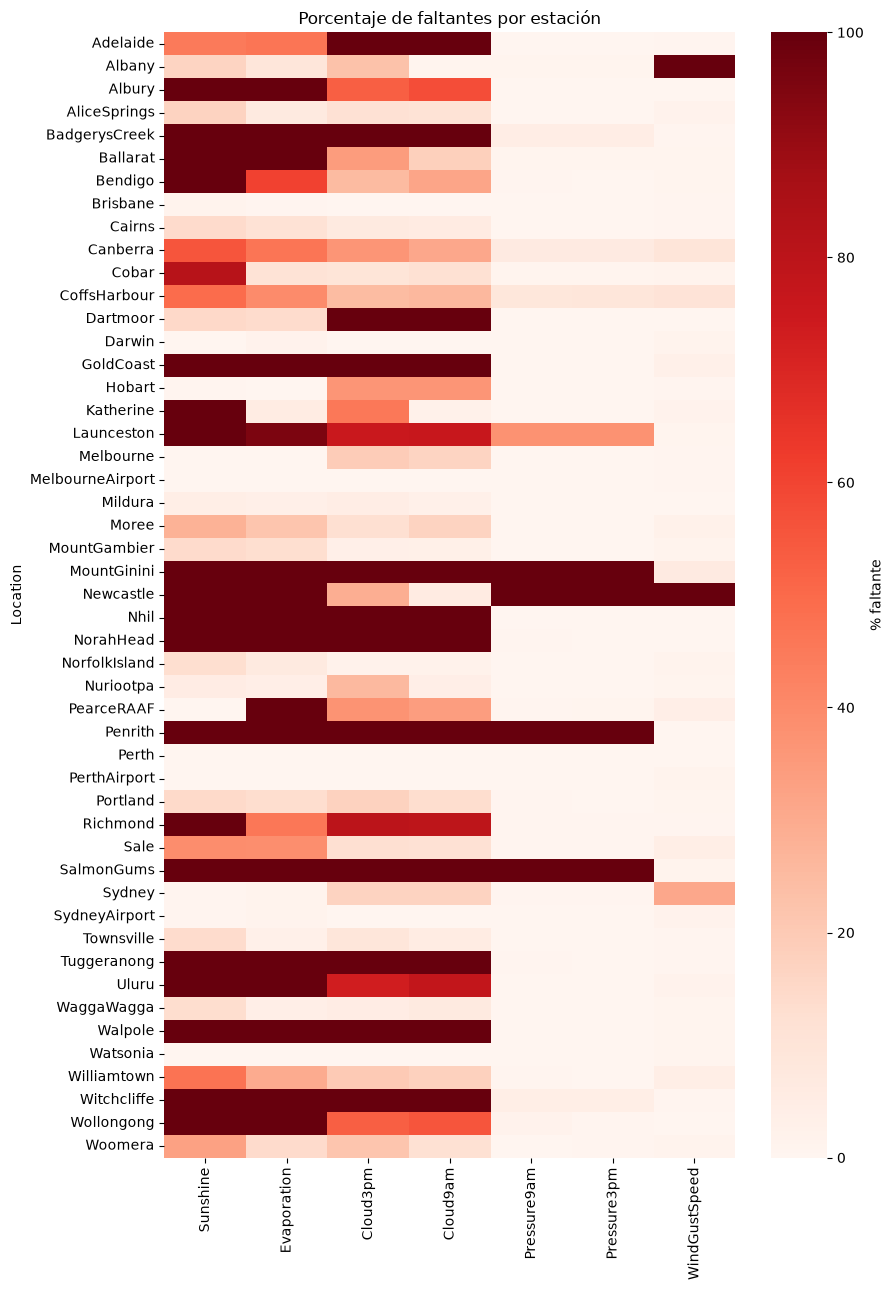

Estaciones que nunca registran cada variable (100 % faltante):
Sunshine         19
Evaporation      16
Cloud3pm         12
Cloud9am         12
Pressure9am       4
Pressure3pm       4
WindGustSpeed     2


In [12]:
cols_incompletas = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am", "Pressure9am", "Pressure3pm", "WindGustSpeed"]
falt_ciudad = data[cols_incompletas].isna().groupby(data["Location"]).mean() * 100

plt.figure(figsize=(9, 13))
sns.heatmap(falt_ciudad, cmap="Reds", vmin=0, vmax=100, cbar_kws={"label": "% faltante"})
plt.title("Porcentaje de faltantes por estación")
plt.tight_layout()
plt.show()

print("Estaciones que nunca registran cada variable (100 % faltante):")
print((falt_ciudad == 100).sum().to_string())

### Decisión sobre los datos faltantes

El diagnóstico muestra tres cosas:

- **Descartar filas no es una opción.** Solo el 39,7 % de las filas está completa, y esas
  filas son de 26 de las 49 estaciones. Eliminar las incompletas tiraría el 60 % de los
  datos y sacaría del dataset a casi la mitad de las estaciones, y el modelo quedaría
  sesgado hacia las mejor equipadas.
- **La falta de datos no es al azar.** En `Sunshine`, `Evaporation` y la nubosidad, el
  faltante depende de la estación: 19 estaciones nunca registran `Sunshine`, 16 nunca
  registran `Evaporation` y 12 nunca registran la nubosidad. Son estaciones que no tienen
  el instrumento.
- **Las variables más incompletas están entre las más informativas.** `Sunshine` y
  `Cloud3pm` son, junto con `Humidity3pm`, las de mayor correlación con el target
  (sección 1.9). Descartar esas columnas perdería justamente la mejor información.

**Decisión:**

1. Se conservan todas las filas y todas las columnas de entrada.
2. Las variables numéricas se imputan con la **mediana** y se agrega un **indicador de
   faltante** por variable. El indicador le permite al modelo distinguir un valor medido de
   uno imputado, lo que importa cuando el faltante depende de la estación.
3. Las direcciones del viento y `RainToday` se pasan primero a números (sección 1.8) y sus
   faltantes se resuelven de la misma forma.
4. La imputación se ajusta **solo con el conjunto de entrenamiento** (sección 1.10).
   Calcular la mediana con todo el dataset filtraría información del conjunto de prueba.

**Alternativas consideradas:**

- Eliminar las filas incompletas: se pierde el 60 % de los datos.
- Eliminar las columnas con más de un 40 % de faltantes: se pierden `Sunshine`,
  `Evaporation` y `Cloud3pm`.
- Imputar con la mediana de cada estación: no resuelve el caso principal, el de las
  estaciones que nunca miden la variable.
- Imputación iterativa o por vecinos: es más costosa, más difícil de reproducir en
  producción y no tiene una ventaja clara para un modelo lineal.

La mediana global con indicador es simple, robusta y se aplica exactamente igual en la
inferencia.

## 1.5 División en entrenamiento, validación y prueba

**Momento de la división.** Se divide ahora, después de la limpieza que no aprende nada
de los datos (descartar columnas y filas sin target) y **antes** de cualquier análisis que
relacione las variables con el target y de cualquier transformación que se ajuste a los
datos (imputación, escalado). Así las decisiones de modelado se toman mirando solo el
conjunto de entrenamiento, y el conjunto de prueba queda como datos que el equipo nunca
vio, igual que los días futuros que va a recibir el modelo en producción.

**División por fecha.** El modelo se usa para predecir días futuros, por eso la división
se hace por fecha y no al azar. Con una división aleatoria, la prueba quedaría intercalada
con el entrenamiento: el modelo vería el día 15 y el 17 de un mes y se lo evaluaría sobre
el 16, algo que nunca va a pasar en producción. Además, los días consecutivos de una
misma estación se parecen mucho, y eso inflaría las métricas. Es el caso de series de
tiempo que se vio en la clase de fuga de datos.

- **Entrenamiento:** hasta el 31/12/2014. Se usa para ajustar los modelos y el preprocesamiento.
- **Validación:** 2015. Se usa para tomar decisiones: elegir el umbral, comparar variantes
  y, en la próxima entrega, optimizar hiperparámetros.
- **Prueba:** desde el 01/01/2016. Se usa solo para la evaluación final.

In [13]:
train = data[data["Date"] <= "2014-12-31"]
val = data[(data["Date"] >= "2015-01-01") & (data["Date"] <= "2015-12-31")]
test = data[data["Date"] >= "2016-01-01"]

assert train["Date"].max() < val["Date"].min() and val["Date"].max() < test["Date"].min()
assert len(train) + len(val) + len(test) == len(data)

display(pd.DataFrame({
    "filas": [len(c) for c in (train, val, test)],
    "pct_del_total": [f"{len(c) / len(data):.1%}" for c in (train, val, test)],
    "pct_llueve": [f"{c[TARGET].mean():.1%}" for c in (train, val, test)],
    "desde": [c["Date"].min().date() for c in (train, val, test)],
    "hasta": [c["Date"].max().date() for c in (train, val, test)],
    "estaciones": [c["Location"].nunique() for c in (train, val, test)],
}, index=["entrenamiento", "validación", "prueba"]))

,filas,pct_del_total,pct_llueve,desde,hasta,estaciones
entrenamiento,98988,69.6%,22.5%,2007-11-01,2014-12-31,49
validación,17231,12.1%,21.2%,2015-01-01,2015-12-31,49
prueba,25934,18.2%,22.9%,2016-01-01,2017-06-24,49


La división queda aproximadamente en 70 / 12 / 18 %. La proporción de días con lluvia es
parecida en los tres conjuntos (entre 21,2 % y 22,9 %) y las 49 estaciones aparecen en
todos. No hace falta estratificar: la división temporal ya mantiene la proporción de
clases. Además, al cortar por años completos, cada conjunto cubre todas las estaciones del
año (validación es exactamente 2015), y la estacionalidad no distorsiona la comparación.

## 1.6 ¿Está balanceado el dataset?

,n,pct
RainTomorrow,,
No,110281,77.6
Yes,31872,22.4


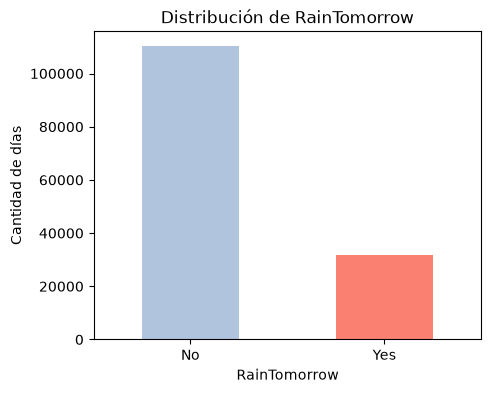

In [14]:
conteo = data[TARGET].map({0: "No", 1: "Yes"}).value_counts()
display(pd.DataFrame({"n": conteo, "pct": (conteo / len(data) * 100).round(1)}))

conteo.plot.bar(color=["lightsteelblue", "salmon"], figsize=(5, 4), rot=0)
plt.title("Distribución de RainTomorrow")
plt.ylabel("Cantidad de días")
plt.show()

**No está balanceado.** El 77,6 % de los días no llueve al día siguiente y el 22,4 % sí,
una relación de 3,5 a 1. No es un desbalance extremo, como el de la detección de fraude,
pero alcanza para afectar tanto el entrenamiento como la evaluación.

¿Por qué importa?

- **Evaluación:** un modelo que responde siempre "no llueve" obtiene alrededor de 78 % de
  accuracy sin aprender nada. La accuracy sola no permite distinguir un modelo útil de uno
  trivial. Hay que mirar métricas por clase (recall, precision, F1) o métricas que no
  dependan de la proporción de clases (balanced accuracy, curvas ROC).
- **Entrenamiento:** la función de costo está dominada por los ejemplos de la clase
  mayoritaria, así que ante la duda el modelo tiende a predecir "no llueve". Se puede
  corregir con pesos en la función de costo (`class_weight`), con remuestreo o moviendo el
  umbral de decisión. En el ítem 2 se comparan los pesos y el umbral. No se usa
  remuestreo: el sobremuestreo simple repite filas y tiene un efecto parecido al de los
  pesos, y el submuestreo descartaría datos reales, lo contrario de lo que buscamos.
- **División:** la proporción tiene que mantenerse parecida en entrenamiento, validación y
  prueba para que las métricas sean comparables. Ya se verificó en la sección 1.5.

## 1.7 Distribuciones, valores extremos y visualizaciones

A partir de acá el análisis se hace **solo sobre el conjunto de entrenamiento**. Primero
el resumen estadístico de las variables numéricas: rango, centro y dispersión.

In [15]:
COLS_MEDIDAS = [
    "MinTemp", "MaxTemp", "Rainfall", "Evaporation", "Sunshine", "WindGustSpeed",
    "WindSpeed9am", "WindSpeed3pm", "Humidity9am", "Humidity3pm", "Pressure9am",
    "Pressure3pm", "Cloud9am", "Cloud3pm", "Temp9am", "Temp3pm",
]
display(train[COLS_MEDIDAS].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
MinTemp,98554.0,12.00,6.37,-9.7,7.5,11.8,16.6,34.1
MaxTemp,98790.0,23.00,7.01,-3.9,17.8,22.4,27.9,49.1
Rainfall,97988.0,2.37,8.52,0.0,0.0,0.0,0.8,371.0
Evaporation,61878.0,5.29,3.95,0.0,2.6,4.6,7.2,82.4
Sunshine,58292.0,7.60,3.79,0.0,4.8,8.4,10.6,14.3
WindGustSpeed,92086.0,40.23,13.76,6.0,31.0,38.0,48.0,135.0
WindSpeed9am,97855.0,14.13,9.02,0.0,7.0,13.0,20.0,88.0
WindSpeed3pm,97848.0,18.77,8.93,0.0,12.0,18.0,24.0,86.0
Humidity9am,97723.0,68.64,19.02,0.0,56.8,69.6,82.8,100.0
Humidity3pm,97802.0,51.49,20.79,0.0,36.7,51.9,65.7,100.0


Los histogramas muestran la forma de la distribución de cada variable numérica.

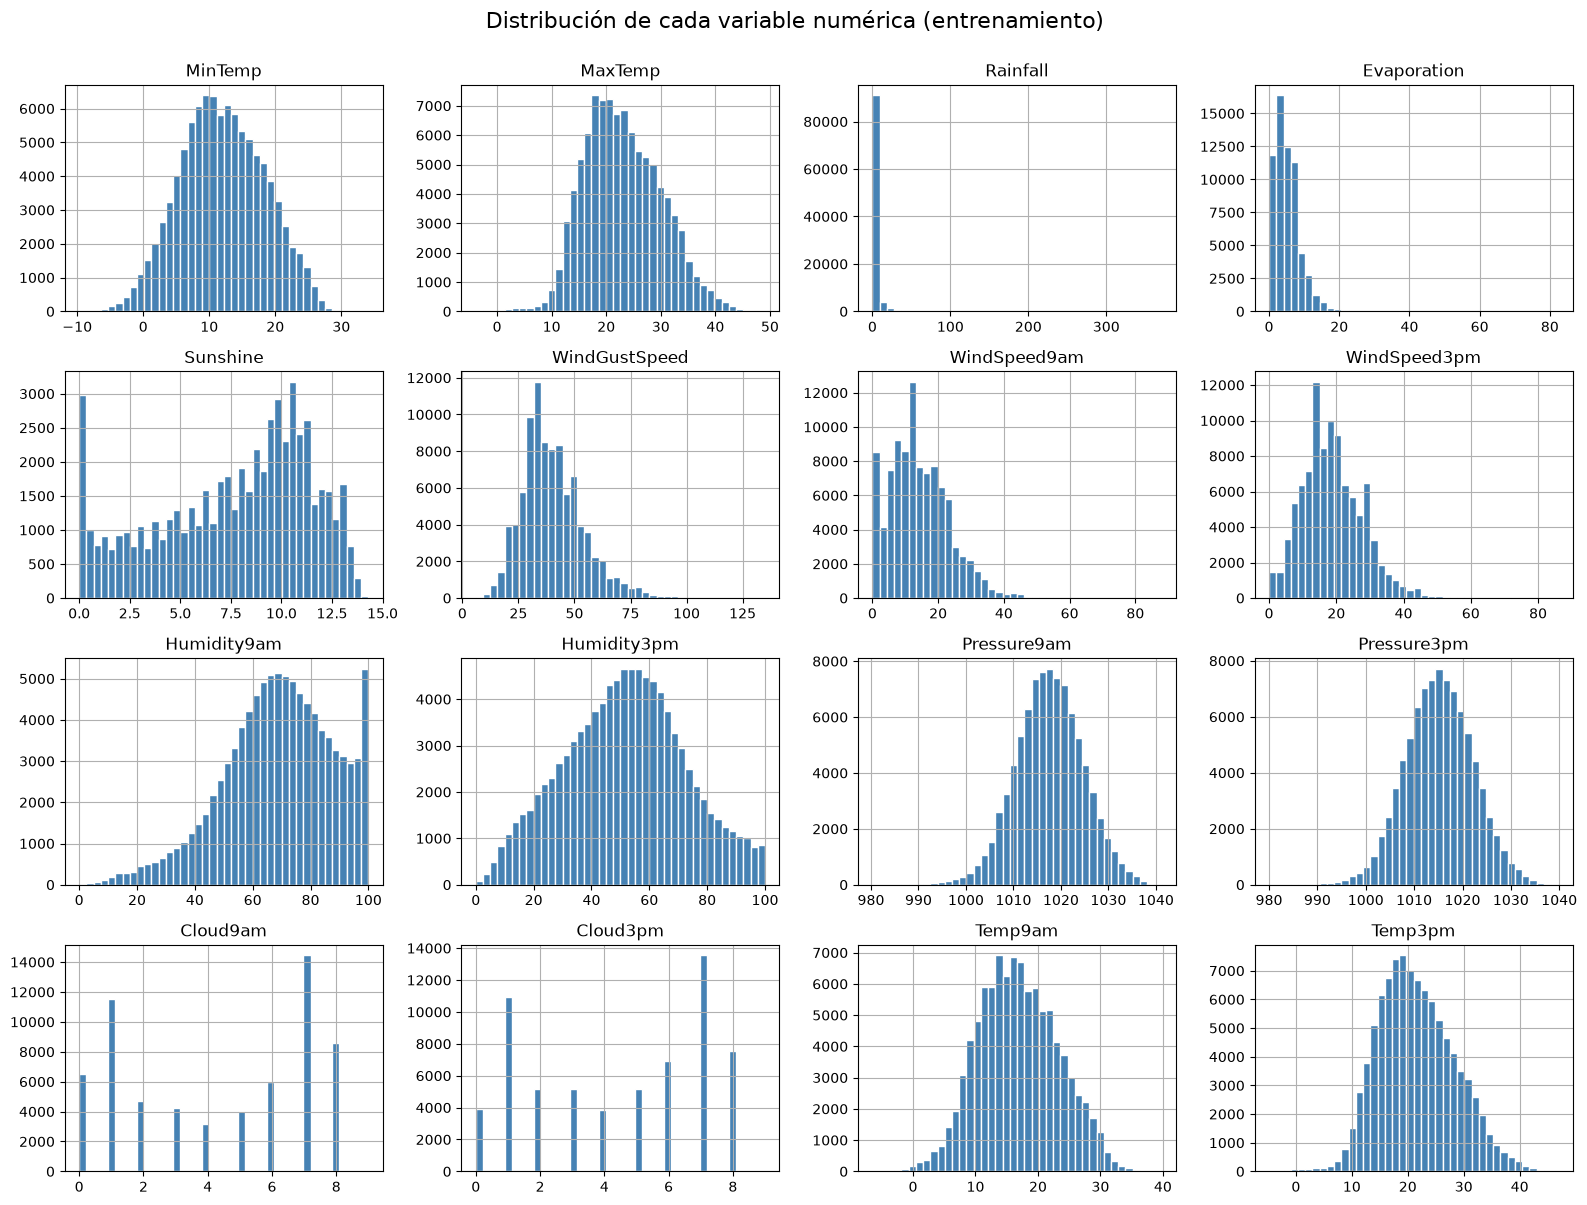

In [16]:
train[COLS_MEDIDAS].hist(bins=40, figsize=(16, 12), color="steelblue", edgecolor="white")
plt.suptitle("Distribución de cada variable numérica (entrenamiento)", fontsize=16, y=1.00)
plt.tight_layout()
plt.show()

In [17]:
print(f"Días con Rainfall = 0: {(train['Rainfall'] == 0).mean():.1%}")
print()
print("Coeficiente de asimetría (skewness):")
print(train[COLS_MEDIDAS].skew().sort_values(ascending=False).round(2).to_string())

Días con Rainfall = 0: 63.3%

Coeficiente de asimetría (skewness):
Rainfall         10.02
Evaporation       3.13
WindGustSpeed     0.87
WindSpeed9am      0.77
WindSpeed3pm      0.60
Temp3pm           0.27
MaxTemp           0.24
Temp9am           0.10
MinTemp           0.03
Humidity3pm       0.02
Pressure3pm      -0.07
Pressure9am      -0.11
Cloud9am         -0.17
Cloud3pm         -0.21
Humidity9am      -0.49
Sunshine         -0.50


Para cuantificar los valores extremos se usa el criterio del boxplot: un valor es atípico
si cae a más de 1,5 rangos intercuartílicos (IQR) por debajo del primer cuartil o por
encima del tercero. El criterio sirve para **detectarlos**, no para decidir que son
errores.

In [18]:
q1 = train[COLS_MEDIDAS].quantile(0.25)
q3 = train[COLS_MEDIDAS].quantile(0.75)
iqr = q3 - q1
fuera_iqr = (train[COLS_MEDIDAS] < q1 - 1.5 * iqr) | (train[COLS_MEDIDAS] > q3 + 1.5 * iqr)

tabla_extremos = pd.DataFrame({
    "n_atipicos": fuera_iqr.sum(),
    "pct_de_medidos": (fuera_iqr.sum() / train[COLS_MEDIDAS].notna().sum() * 100).round(2),
    "limite_inferior": (q1 - 1.5 * iqr).round(1),
    "limite_superior": (q3 + 1.5 * iqr).round(1),
    "maximo": train[COLS_MEDIDAS].max(),
}).sort_values("n_atipicos", ascending=False)
display(tabla_extremos)

,n_atipicos,pct_de_medidos,limite_inferior,limite_superior,maximo
Rainfall,17677,18.04,-1.2,2.0,371.0
WindGustSpeed,2149,2.33,5.5,73.5,135.0
Evaporation,1619,2.62,-4.3,14.1,82.4
WindSpeed3pm,1201,1.23,-6.0,42.0,86.0
WindSpeed9am,1089,1.11,-12.5,39.5,88.0
Humidity9am,1074,1.10,17.8,121.8,100.0
Pressure9am,807,0.90,998.6,1036.6,1041.2
Pressure3pm,673,0.75,996.2,1034.2,1039.8
Temp3pm,580,0.59,2.0,40.8,46.9
MaxTemp,437,0.44,2.7,43.0,49.1


In [19]:
display(train.nlargest(5, "Rainfall")[["Date", "Location", "Rainfall", "Humidity3pm", TARGET]])

evaporacion_alta = train.loc[train["Evaporation"] > 40, "Date"].dt.day_name()
print(f"Días con Evaporation > 40 mm: {len(evaporacion_alta)}")
print(evaporacion_alta.value_counts().to_string())

,Date,Location,Rainfall,Humidity3pm,RainTomorrow
9233,2009-11-07,CoffsHarbour,371.0,82.1,1
136841,2011-02-16,Darwin,367.6,97.9,1
84869,2009-01-12,Cairns,278.4,98.0,1
85622,2011-02-04,Cairns,268.6,86.3,1
90857,2009-02-03,Townsville,236.8,94.9,1


Días con Evaporation > 40 mm: 50
Date
Monday       24
Sunday       11
Tuesday      10
Saturday      3
Thursday      1
Wednesday     1


- **`Rainfall`:** el criterio del boxplot marca el 18 % de los valores como atípicos,
  porque el 63 % de los días vale 0 y el rango intercuartílico es de apenas 0,8 mm:
  cualquier lluvia de más de 2 mm queda "fuera". El criterio no sirve para una variable
  con tantos ceros y una cola tan larga. Los máximos (371 mm en Coffs Harbour, 368 mm en
  Darwin, 278 mm en Cairns) son tormentas tropicales y subtropicales reales, con humedad
  alta y lluvia también al día siguiente.
- **`Evaporation`:** hay valores de hasta 82 mm en el entrenamiento, muy por encima de lo
  que se evapora en un día. De los 50 días con más de 40 mm, 24 son lunes y 11 domingos,
  cuando cada día de la semana representa alrededor del 14 % de las mediciones. Todo indica
  que son acumulados de varios días en estaciones donde el tanque no se lee el fin de
  semana: no son errores de tipeo, sino mediciones de un período más largo. Representan
  menos del 0,1 % de las mediciones. Se conservan: no afectan la mediana usada para
  imputar, y si en la explicabilidad (ítem 5) `Evaporation` mostrara un peso anómalo, se
  podría acotar la variable.
- **Viento:** ráfagas de hasta 135 km/h y vientos medios de hasta 88 km/h, compatibles con
  temporales fuertes en la costa este. Se conservan.
- **Presión, temperaturas y humedad:** pocos atípicos (menos del 1,2 % en cada variable) y
  dentro de rangos físicamente posibles, como presiones de 980 hPa con el paso de sistemas
  de baja presión o máximas de 49 °C en el interior.

**Decisión:** no se elimina ninguna observación por ser extrema. En meteorología, un valor
poco frecuente suele ser justamente el evento que interesa predecir.

Para un problema de clasificación interesa sobre todo qué variables se comportan distinto
el día previo a una lluvia. Los diagramas de caja comparan cada variable según el target.

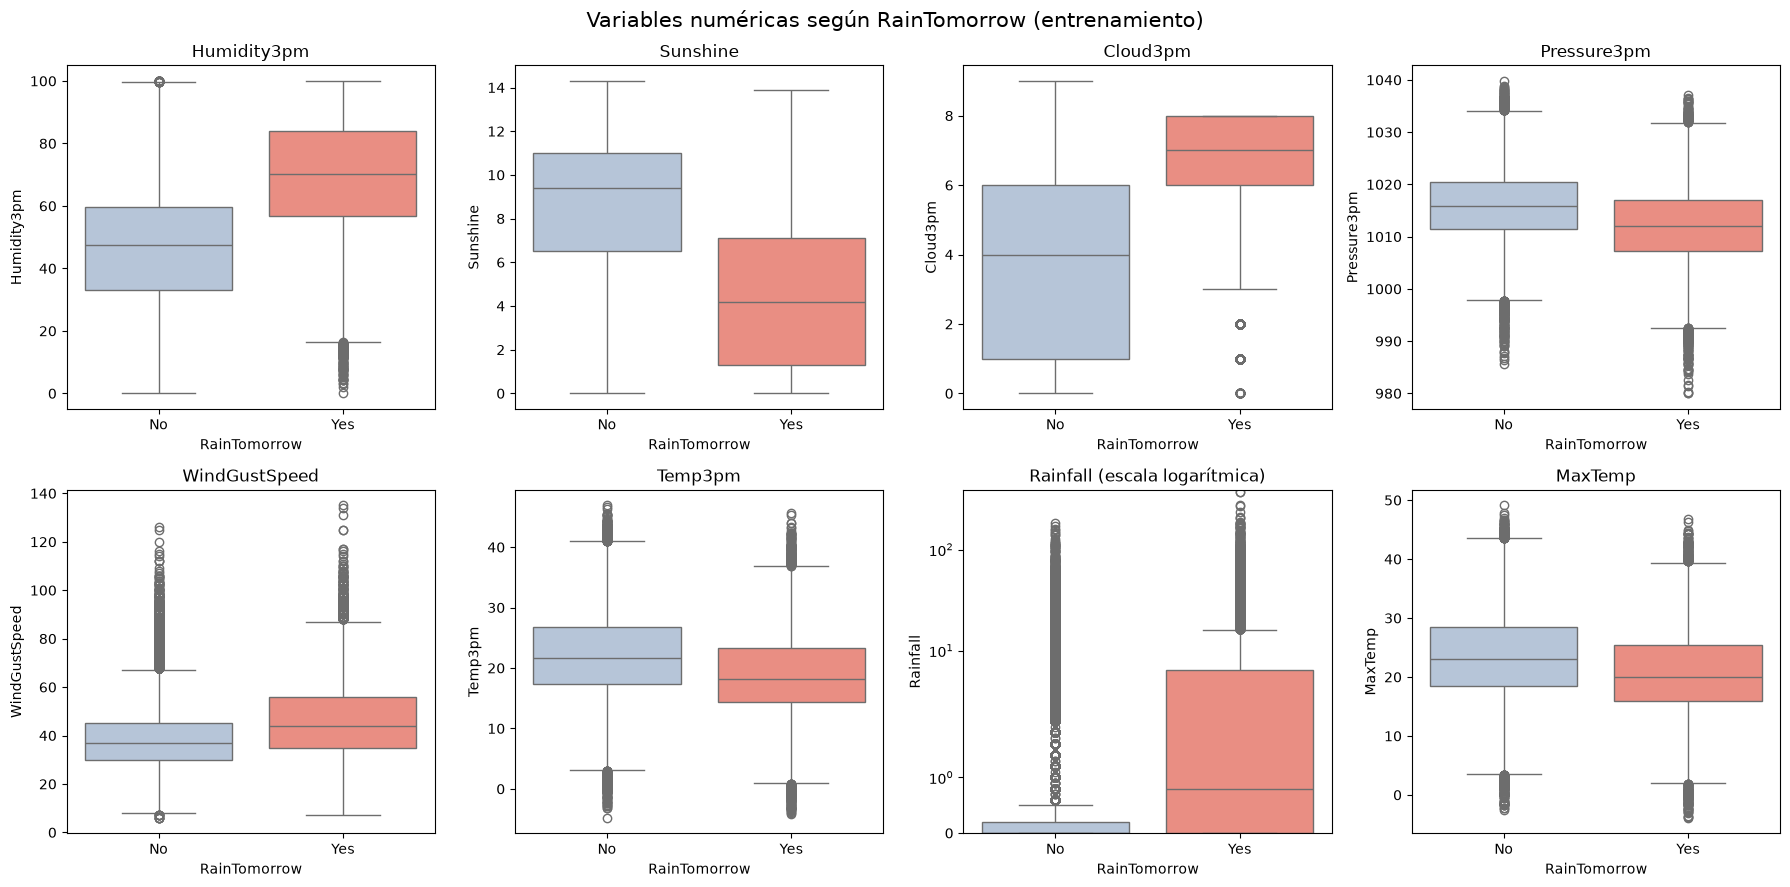

Mediana de cada variable según RainTomorrow:


,Humidity3pm,Sunshine,Cloud3pm,Pressure3pm,WindGustSpeed,Temp3pm,Rainfall,MaxTemp
RainTomorrow,,,,,,,,
No,47.4,9.4,4.0,1015.9,37.0,21.7,0.0,23.1
Yes,70.1,4.2,7.0,1012.1,44.0,18.2,0.8,20.0


In [20]:
train_eda = train.assign(RainTomorrow=train[TARGET].map({0: "No", 1: "Yes"}))
paleta = {"No": "lightsteelblue", "Yes": "salmon"}

cols_box = ["Humidity3pm", "Sunshine", "Cloud3pm", "Pressure3pm",
            "WindGustSpeed", "Temp3pm", "Rainfall", "MaxTemp"]
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, col in zip(axes.ravel(), cols_box):
    sns.boxplot(data=train_eda, x="RainTomorrow", y=col, ax=ax, hue="RainTomorrow",
                palette=paleta, legend=False)
    ax.set_title(col)
axes[1, 2].set_yscale("symlog")
axes[1, 2].set_ylim(bottom=0)
axes[1, 2].set_title("Rainfall (escala logarítmica)")
plt.suptitle("Variables numéricas según RainTomorrow (entrenamiento)", fontsize=15)
plt.tight_layout()
plt.show()

print("Mediana de cada variable según RainTomorrow:")
display(train_eda.groupby("RainTomorrow")[cols_box].median().round(1))

Para las variables categóricas se mira la proporción de días previos a una lluvia para
cada valor. Si la proporción cambia mucho entre categorías, la variable aporta
información.

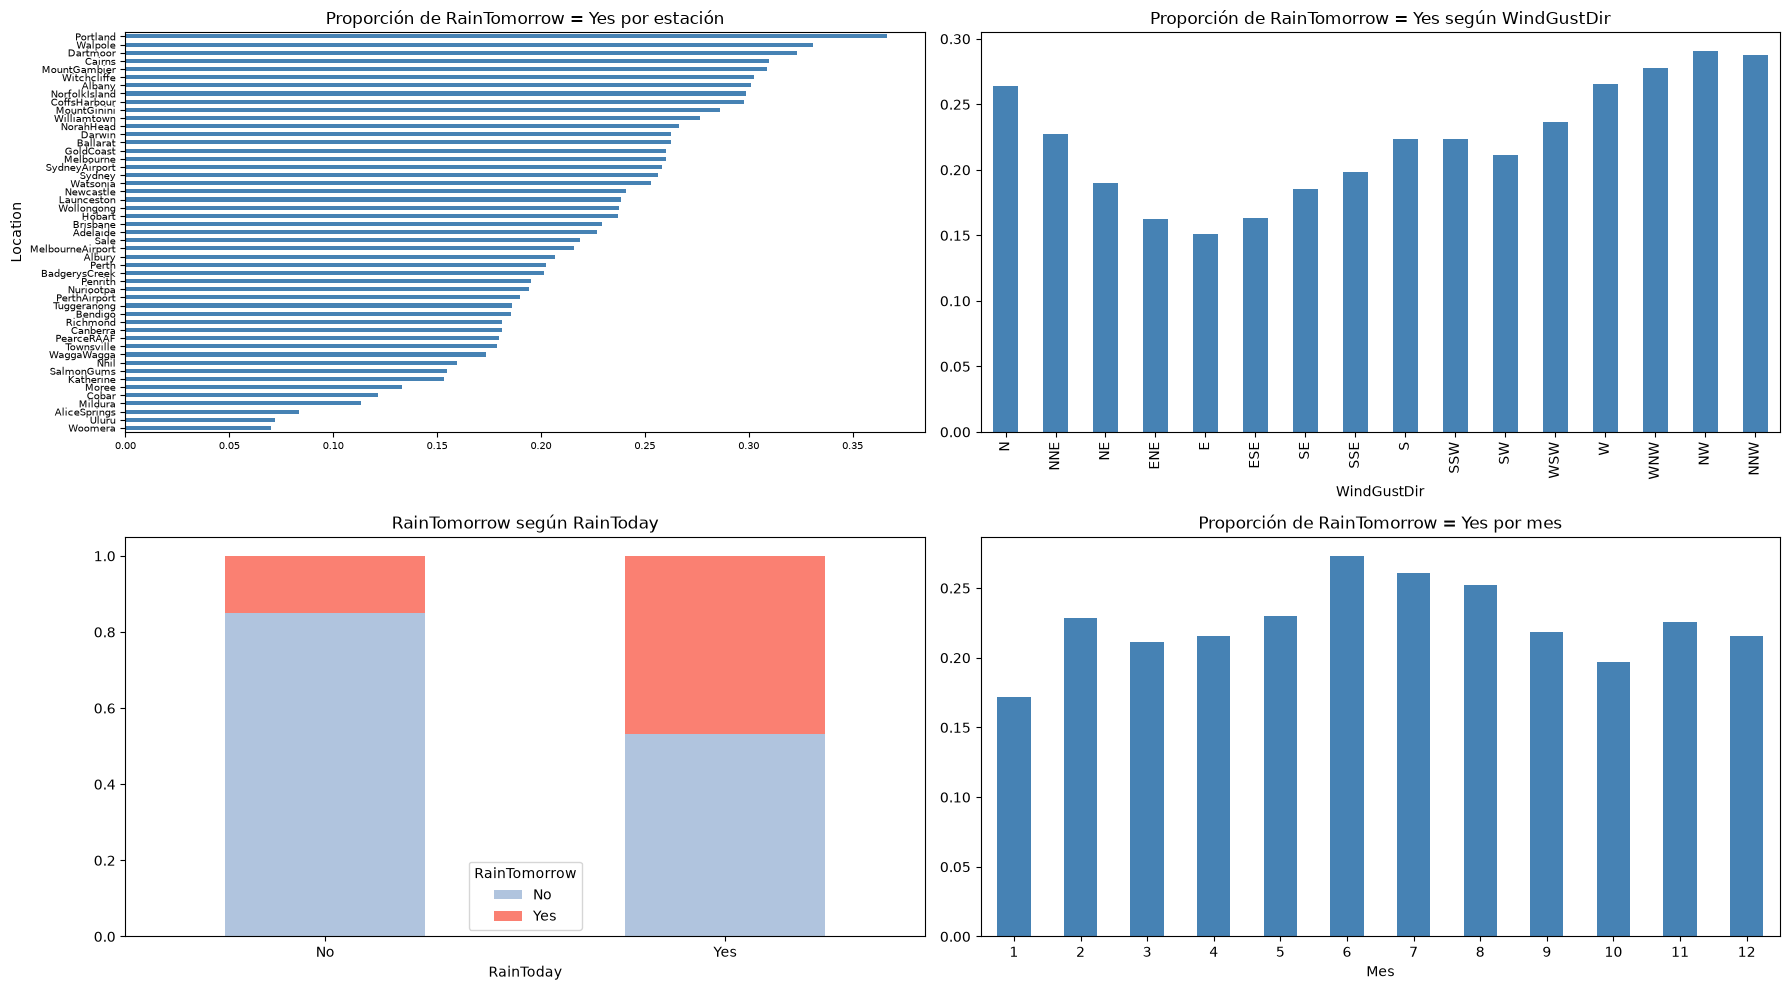

Estación con menos lluvia: Woomera (7.0%)   con más: Portland (36.6%)
RainToday
No     0.151
Yes    0.468


In [21]:
ORDEN_RUMBOS = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
                "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]

fig, axes = plt.subplots(2, 2, figsize=(18, 10))

tasa_estacion = train[TARGET].groupby(train["Location"]).mean().sort_values()
tasa_estacion.plot.barh(ax=axes[0, 0], color="steelblue", fontsize=7)
axes[0, 0].set_title("Proporción de RainTomorrow = Yes por estación")

train[TARGET].groupby(train["WindGustDir"]).mean().reindex(ORDEN_RUMBOS).plot.bar(
    ax=axes[0, 1], color="steelblue")
axes[0, 1].set_title("Proporción de RainTomorrow = Yes según WindGustDir")

pd.crosstab(train["RainToday"], train_eda["RainTomorrow"], normalize="index").plot.bar(
    ax=axes[1, 0], stacked=True, color=["lightsteelblue", "salmon"], rot=0)
axes[1, 0].set_title("RainTomorrow según RainToday")

train[TARGET].groupby(train["Date"].dt.month).mean().plot.bar(ax=axes[1, 1], color="steelblue", rot=0)
axes[1, 1].set_title("Proporción de RainTomorrow = Yes por mes")
axes[1, 1].set_xlabel("Mes")

plt.tight_layout()
plt.show()

print(f"Estación con menos lluvia: {tasa_estacion.index[0]} ({tasa_estacion.iloc[0]:.1%})   "
      f"con más: {tasa_estacion.index[-1]} ({tasa_estacion.iloc[-1]:.1%})")
print(train[TARGET].groupby(train["RainToday"]).mean().round(3).to_string())

Los diagramas de dispersión muestran pares de variables coloreados por el target. Se usa
una muestra de 5000 filas de entrenamiento porque con casi 100 mil puntos el gráfico se
satura.

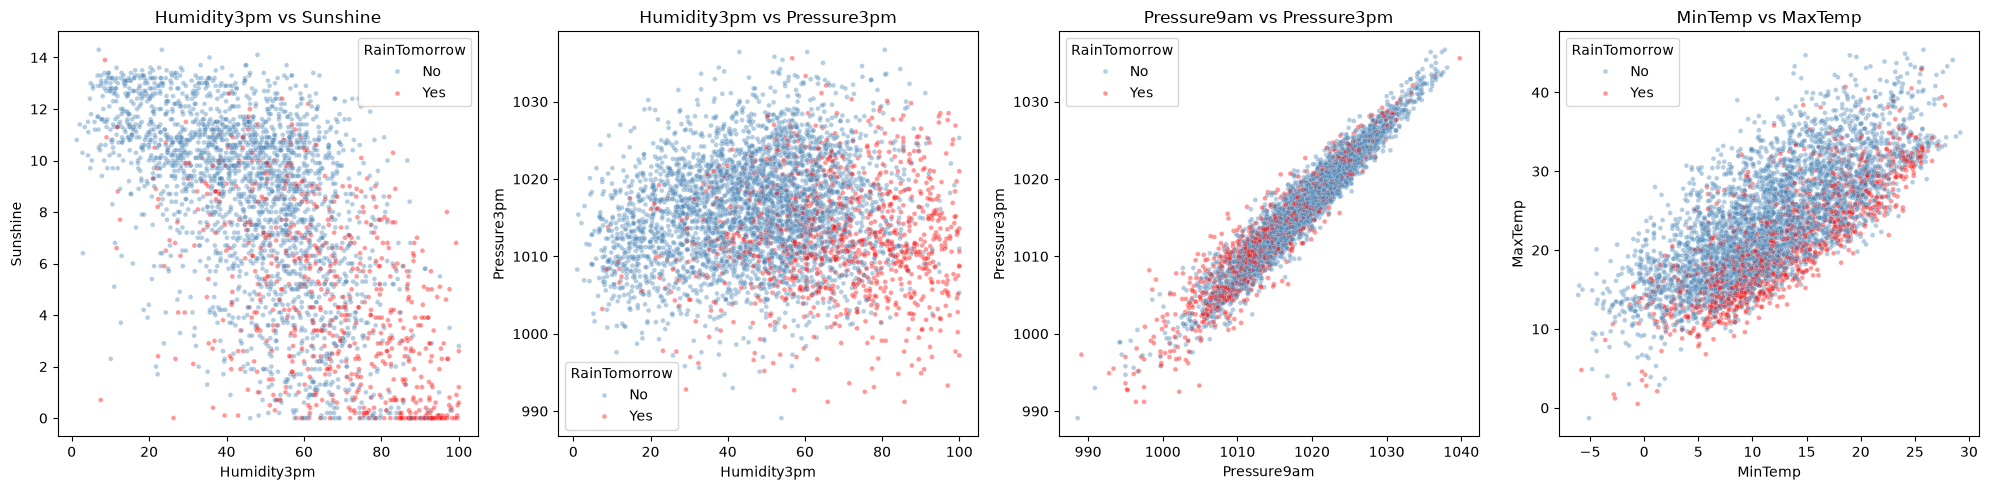

In [22]:
muestra = train_eda.sample(5000, random_state=RANDOM_STATE)
pares = [("Humidity3pm", "Sunshine"), ("Humidity3pm", "Pressure3pm"),
         ("Pressure9am", "Pressure3pm"), ("MinTemp", "MaxTemp")]
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, (x, y) in zip(axes, pares):
    sns.scatterplot(data=muestra, x=x, y=y, hue="RainTomorrow", alpha=0.4, s=12, ax=ax,
                    palette={"No": "steelblue", "Yes": "red"})
    ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

#### Lectura de las variables (entrenamiento)

| Variable | Rango | Comportamiento |
|---|---|---|
| `MinTemp`, `MaxTemp` | -9,7 a 34,1 °C / -3,9 a 49,1 °C | Aproximadamente simétricas. Los días previos a una lluvia son más frescos: la mediana de `MaxTemp` baja de 23,1 a 20,0 °C. |
| `Temp9am`, `Temp3pm` | -6,5 a 39,8 °C / -4,8 a 46,9 °C | Simétricas y casi redundantes con la mínima y la máxima (sección 1.9). `Temp3pm` baja de 21,7 a 18,2 °C antes de un día de lluvia. |
| `Rainfall` | 0 a 371 mm | Muy asimétrica (skewness de 10): el 63 % de los días vale 0 y unos pocos superan los 200 mm. Mediana de 0 mm antes de un día seco y de 0,8 mm antes de uno de lluvia: la lluvia tiende a persistir. |
| `Evaporation` | 0 a 82 mm | Asimétrica a la derecha, con valores acumulados de varios días (ver arriba). Falta en el 43 % de los días. |
| `Sunshine` | 0 a 14,3 h | Asimétrica a la izquierda: la mayoría de los días son soleados. Es la variable que más se separa entre clases: mediana de 9,4 h antes de un día seco y de 4,2 h antes de uno de lluvia. |
| `WindGustSpeed` | 6 a 135 km/h | Cola a la derecha. Las ráfagas son más fuertes antes de un día de lluvia (mediana de 44 contra 37 km/h). |
| `WindSpeed9am`, `WindSpeed3pm` | 0 a 88 km/h / 0 a 86 km/h | Cola a la derecha, con muchos momentos de calma (0 km/h). |
| `Humidity9am`, `Humidity3pm` | 0 a 100 % | `Humidity3pm` es casi simétrica y muy discriminante: mediana de 47,4 % antes de un día seco y de 70,1 % antes de uno de lluvia. |
| `Pressure9am`, `Pressure3pm` | 980 a 1041 hPa | Casi normales. La presión baja antes de un día de lluvia (mediana de 1015,9 contra 1012,1 hPa a las 3 pm), por el paso de frentes y sistemas de baja presión. |
| `Cloud9am`, `Cloud3pm` | 0 a 8 octavos (y 3 valores de 9) | Discretas y bimodales, concentradas en cielo despejado (0–1) y cubierto (7–8). Antes de un día de lluvia la mediana de `Cloud3pm` sube de 4 a 7. |
| Direcciones del viento | 16 rumbos | Con ráfagas del NW, NNW o WNW llueve al día siguiente en alrededor del 28–29 % de los casos; con ráfagas del E, solo en el 15 %. |
| `Location` | 49 estaciones | La proporción de días con lluvia va del 7,0 % (Woomera, en el desierto) al 36,6 % (Portland, en la costa sur). La ubicación pesa mucho. |
| `RainToday` | Yes / No | Si hoy llovió, mañana llueve en el 46,8 % de los casos; si no, en el 15,1 %. |
| Mes | 1 a 12 | Estacionalidad moderada: en el invierno austral (junio–agosto) llueve al día siguiente en el 25–27 % de los días, contra un 17 % en enero. |

Los diagramas de dispersión confirman lo anterior. Los días previos a una lluvia se
concentran en la zona de humedad alta y poco sol, y en la de humedad alta y presión baja.
Las dos presiones forman casi una recta, porque son prácticamente la misma información
medida con seis horas de diferencia.

## 1.8 Ingeniería y codificación de variables

Las transformaciones que no aprenden nada de los datos se agrupan en una única función,
`crear_variables`, que recibe las columnas originales tal como vienen en el CSV:

- **Direcciones del viento → seno y coseno del ángulo.** Los 16 rumbos forman una
  variable circular: N y NNW están a 22,5° de distancia, pero un código ordinal (0 y 15)
  los pondría en extremos opuestos. Con el seno y el coseno, los rumbos vecinos quedan
  cerca, y se usan 2 columnas por variable en lugar de 16.
- **Mes → seno y coseno.** El gráfico por mes muestra estacionalidad, y el mes también
  es circular: diciembre está al lado de enero.
- **`RainToday` → 0/1.**
- **Nubosidad de 9 octavos → faltante.** La escala de octavos llega a 8; el 9 indica que
  el cielo no se pudo observar. Tratarlo como "más que cubierto" sería incorrecto, así que
  se convierte en faltante y lo resuelve el imputador. No se elimina la fila.
- **`Location`** se conserva como texto y se codifica con one-hot en el paso siguiente.

La función se usa como primer paso del pipeline del modelo, con un `FunctionTransformer`.
Como no aprende nada de los datos, aplicarla antes o después de la división da lo mismo.
Lo importante es que **forme parte del modelo**: así el contenedor de Docker (ítem 9)
recibe los datos crudos y aplica exactamente las mismas transformaciones que se usaron
para entrenar, sin una segunda implementación.

`Date` solo se usa para obtener el mes. El año no entra al modelo, porque en producción
siempre sería un año que el modelo no vio.

In [23]:
ANGULO_RUMBO = {rumbo: i * 22.5 for i, rumbo in enumerate(ORDEN_RUMBOS)}
COLS_VIENTO = ["WindGustDir", "WindDir9am", "WindDir3pm"]
COLS_NUBES = ["Cloud9am", "Cloud3pm"]
COLS_ENTRADA = ["Date", "Location"] + COLS_MEDIDAS + COLS_VIENTO + ["RainToday"]


def crear_variables(df):
    salida = df[COLS_MEDIDAS].copy()
    salida[COLS_NUBES] = salida[COLS_NUBES].where(salida[COLS_NUBES] <= 8)
    salida["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1})
    for col in COLS_VIENTO:
        radianes = np.deg2rad(df[col].map(ANGULO_RUMBO))
        salida[f"{col}_sin"] = np.sin(radianes)
        salida[f"{col}_cos"] = np.cos(radianes)
    mes = pd.to_datetime(df["Date"]).dt.month
    salida["Month_sin"] = np.sin(2 * np.pi * mes / 12)
    salida["Month_cos"] = np.cos(2 * np.pi * mes / 12)
    salida["Location"] = df["Location"]
    return salida


variables_train = crear_variables(train)
COLS_NUM = [c for c in variables_train.columns if c != "Location"]
COLS_CAT = ["Location"]

print(f"Columnas de entrada: {len(COLS_ENTRADA)}   numéricas creadas: {len(COLS_NUM)}   categóricas: {len(COLS_CAT)}")
print(f"Valores de nubosidad = 9 convertidos en faltante (entrenamiento): "
      f"{int((train[COLS_NUBES] > 8).sum().sum())}")
display(pd.concat([train[["Date", "WindGustDir", "RainToday"]], variables_train[["WindGustDir_sin", "WindGustDir_cos", "Month_sin", "Month_cos", "RainToday"]].add_suffix("_nueva")], axis=1).head())

Columnas de entrada: 22   numéricas creadas: 25   categóricas: 1
Valores de nubosidad = 9 convertidos en faltante (entrenamiento): 3


,Date,WindGustDir,RainToday,WindGustDir_sin_nueva,WindGustDir_cos_nueva,Month_sin_nueva,Month_cos_nueva,RainToday_nueva
0,2008-12-01,W,No,-1.000000,-1.836970e-16,-2.449294e-16,1.0,0.0
1,2008-12-02,WNW,No,-0.923880,3.826834e-01,-2.449294e-16,1.0,0.0
2,2008-12-03,WSW,No,-0.923880,-3.826834e-01,-2.449294e-16,1.0,0.0
3,2008-12-04,NE,No,0.707107,7.071068e-01,-2.449294e-16,1.0,0.0
4,2008-12-05,W,No,-1.000000,-1.836970e-16,-2.449294e-16,1.0,0.0


**`Location`: one-hot sobre las 49 estaciones.** La proporción de días con lluvia varía
mucho entre estaciones, así que la ubicación es muy informativa. Cada estación tiene al
menos 1.500 observaciones en el dataset, y con unas 100 mil filas de entrenamiento 49
columnas binarias no son un problema para una regresión logística. Se descartó agruparlas
en regiones: sería una agrupación hecha a mano, que pierde la diferencia entre estaciones
vecinas y no aporta una ventaja clara. Con `handle_unknown="ignore"`, una estación que no
apareció en el entrenamiento se codifica con todas las columnas en 0 y el modelo no falla.

`RainTomorrow` ya está en 0/1 (sección 1.3).

## 1.9 Matriz de correlación

Se calcula sobre el conjunto de entrenamiento, con las variables numéricas ya
transformadas (antes de imputar) y el target.

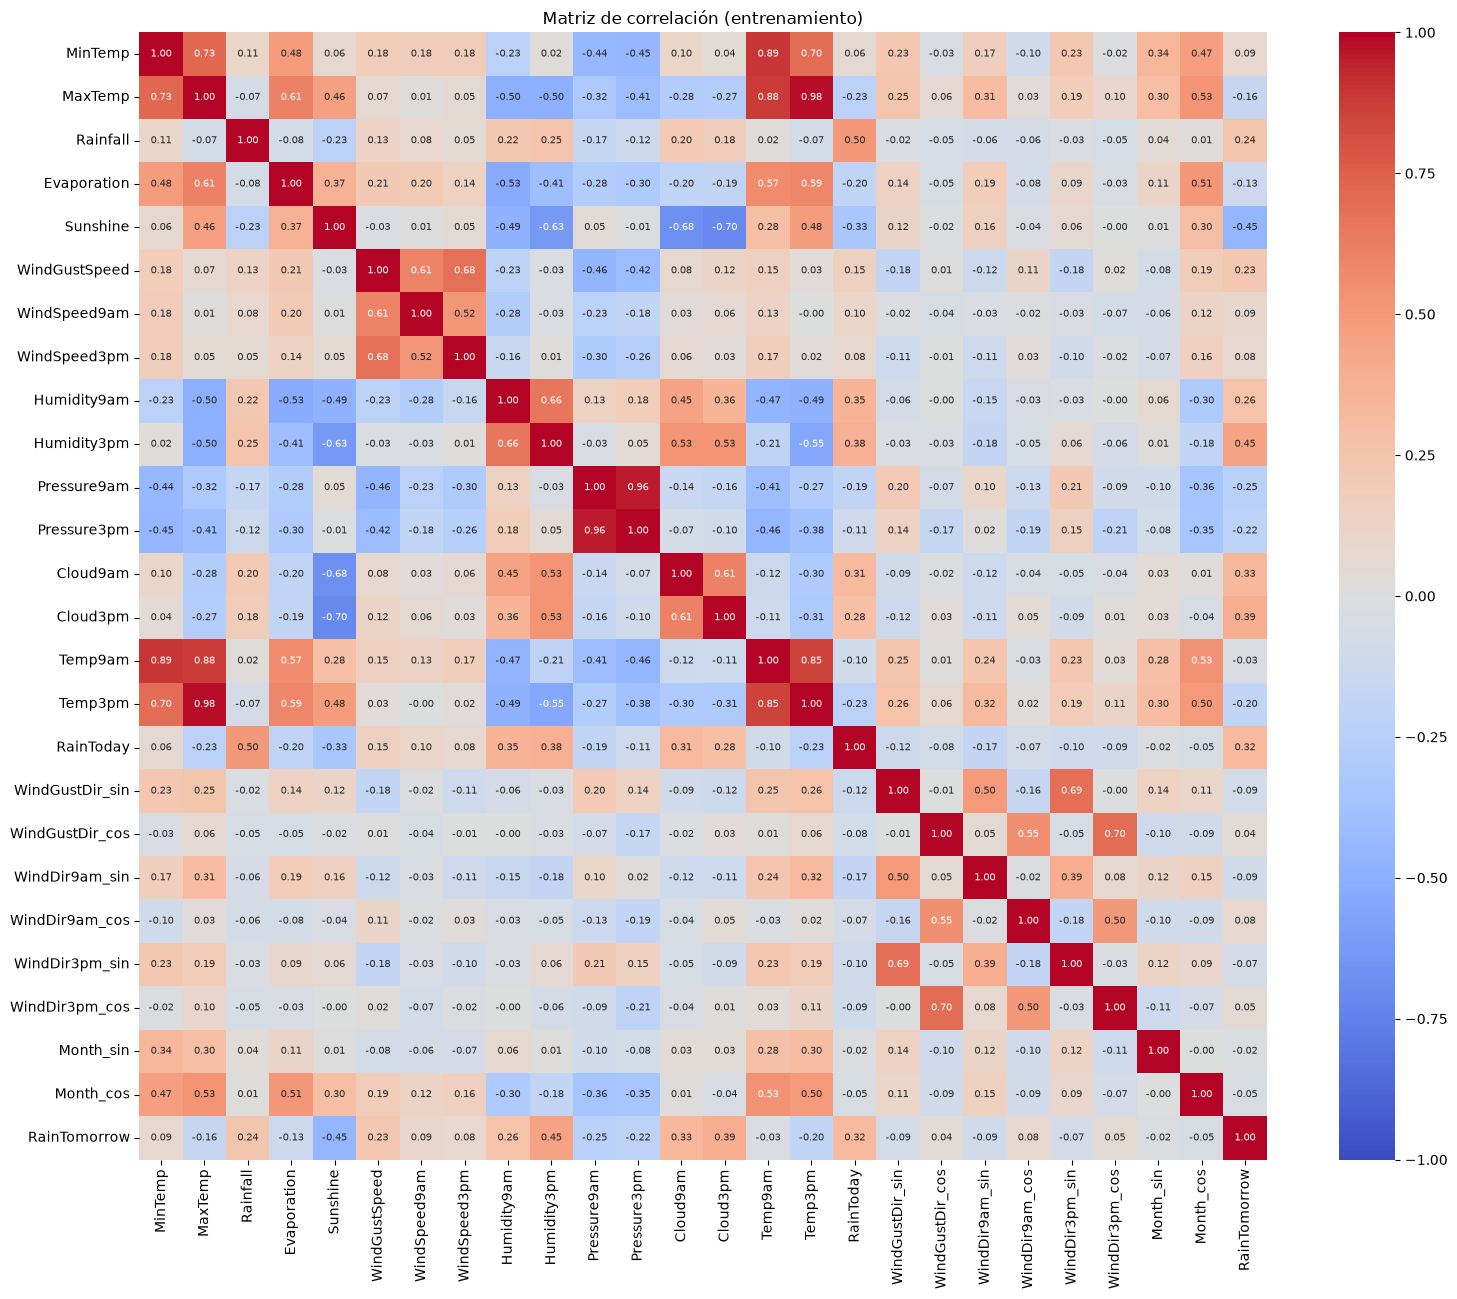

In [24]:
corr_matrix = variables_train[COLS_NUM].assign(RainTomorrow=train[TARGET]).corr()
plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, annot_kws={"size": 7})
plt.title("Matriz de correlación (entrenamiento)")
plt.tight_layout()
plt.show()

In [25]:
corr_target = corr_matrix[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
print("Correlación con RainTomorrow:")
print(corr_target.round(3).to_string())

print("\nPares de predictores con |correlación| > 0.7:")
for i, a in enumerate(COLS_NUM):
    for b in COLS_NUM[i + 1:]:
        if abs(corr_matrix.loc[a, b]) > 0.7:
            print(f"  {a:15s} - {b:15s} {corr_matrix.loc[a, b]:.2f}")

Correlación con RainTomorrow:
Sunshine          -0.454
Humidity3pm        0.448
Cloud3pm           0.393
Cloud9am           0.329
RainToday          0.318
Humidity9am        0.260
Pressure9am       -0.247
Rainfall           0.245
WindGustSpeed      0.231
Pressure3pm       -0.224
Temp3pm           -0.196
MaxTemp           -0.164
Evaporation       -0.126
WindSpeed9am       0.092
WindDir9am_sin    -0.090
WindGustDir_sin   -0.086
MinTemp            0.086
WindSpeed3pm       0.085
WindDir9am_cos     0.079
WindDir3pm_sin    -0.066
WindDir3pm_cos     0.051
Month_cos         -0.047
WindGustDir_cos    0.042
Temp9am           -0.027
Month_sin         -0.016

Pares de predictores con |correlación| > 0.7:
  MinTemp         - MaxTemp         0.73
  MinTemp         - Temp9am         0.89
  MaxTemp         - Temp9am         0.88
  MaxTemp         - Temp3pm         0.98
  Sunshine        - Cloud3pm        -0.70
  Pressure9am     - Pressure3pm     0.96
  Temp9am         - Temp3pm         0.85
  WindGust

- Las variables más asociadas con la lluvia del día siguiente son **`Sunshine`** (-0,45),
  **`Humidity3pm`** (0,45), **`Cloud3pm`** (0,39) y **`RainToday`** (0,32). Coincide con
  los diagramas de caja: la tarde previa a una lluvia es húmeda, nublada y con poco sol.
- La presión correlaciona negativamente (-0,25 a las 9 am): la presión baja acompaña a los
  frentes de mal tiempo.
- `RainToday` correlaciona más con el target que `Rainfall` (0,32 contra 0,25), aunque
  proviene de ella. El efecto de la lluvia de hoy no crece en forma lineal con los
  milímetros, y el umbral de 1 mm resume mejor la información. Se conservan ambas.
- Los senos y cosenos del viento y del mes tienen correlaciones lineales chicas (menores
  a 0,1). Eso no quiere decir que no sirvan. La correlación mide solo la relación lineal
  de cada componente por separado, y el gráfico por rumbo mostró diferencias claras: 15 %
  de lluvia con ráfagas del E contra 29 % con ráfagas del NW.
- **Colinealidad:** las cuatro temperaturas están muy correlacionadas entre sí
  (`MaxTemp`–`Temp3pm` 0,98, `MinTemp`–`Temp9am` 0,89), y lo mismo pasa con las dos
  presiones (0,96). También `Sunshine` con `Cloud3pm` (-0,70). Por ahora se mantienen todas.
  La regresión logística de scikit-learn aplica regularización L2 por defecto, que reparte
  el peso entre variables correlacionadas en lugar de inflar los coeficientes. Además,
  muchas se complementan cuando faltan: en las estaciones sin `Sunshine`, la nubosidad o la
  humedad aportan una información parecida. En los ítems 4 y 5 (optimización y
  explicabilidad) se va a revisar si conviene descartar alguna.

## 1.10 Imputación, codificación y estandarización

Todo el preprocesamiento que aprende de los datos va en un `ColumnTransformer`, que se
ajusta **solo con el conjunto de entrenamiento** y se aplica igual a validación y a
prueba:

- **Numéricas:** imputación por la **mediana** del entrenamiento, robusta a las colas
  largas de `Rainfall` y `Evaporation`. Con `add_indicator=True` se agrega una columna
  0/1 por cada variable que tenía faltantes, para que el modelo sepa cuándo un valor fue
  imputado. Después, `StandardScaler`. La regresión logística de scikit-learn aplica
  regularización L2 por defecto: sin escalar, las variables con números grandes (la
  presión, alrededor de 1000) y las chicas (los senos, entre -1 y 1) quedarían
  penalizadas de forma distinta. El escalado también ayuda a que el optimizador converja.
- **`Location`:** imputación por la moda (hoy no tiene faltantes, pero así el pipeline
  soporta uno en producción) y one-hot.

Las prácticas de la materia escalan "a mano", con `fit_transform` sobre el entrenamiento y
`transform` sobre la prueba. `Pipeline` y `ColumnTransformer` hacen exactamente lo mismo,
pero dentro de un único objeto. Así se evita ajustar por error una transformación con
datos de validación o prueba, y ese mismo objeto se puede guardar para el despliegue.

A continuación se separan las entradas del target en los tres conjuntos y se ajusta la
transformación completa sobre el entrenamiento para verificar el resultado.

In [26]:
preprocesador = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ]), COLS_NUM),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), COLS_CAT),
])

X_train, y_train = train[COLS_ENTRADA], train[TARGET]
X_val, y_val = val[COLS_ENTRADA], val[TARGET]
X_test, y_test = test[COLS_ENTRADA], test[TARGET]

transformacion = Pipeline([
    ("variables", FunctionTransformer(crear_variables)),
    ("prep", clone(preprocesador)),
]).fit(X_train)

X_train_prep = transformacion.transform(X_train)
nombres_prep = transformacion.named_steps["prep"].get_feature_names_out()
n_numericas = sum(n.startswith("num__") for n in nombres_prep)

print(f"Columnas de entrada: {X_train.shape[1]}   después del preprocesamiento: {X_train_prep.shape[1]}")
print(f"  numéricas: {len(COLS_NUM)}   indicadores de faltante: {n_numericas - len(COLS_NUM)}   one-hot de Location: {X_train_prep.shape[1] - n_numericas}")
print(f"Media máxima |x| de las numéricas en entrenamiento: {np.abs(X_train_prep[:, :n_numericas].mean(axis=0)).max():.2e}")
print(f"Desvío medio de las numéricas en entrenamiento: {X_train_prep[:, :n_numericas].std(axis=0).mean():.3f}")
for nombre, X in [("entrenamiento", X_train), ("validación", X_val), ("prueba", X_test)]:
    print(f"Faltantes después de transformar ({nombre}): {np.isnan(transformacion.transform(X)).sum()}")

Columnas de entrada: 22   después del preprocesamiento: 97
  numéricas: 25   indicadores de faltante: 23   one-hot de Location: 49
Media máxima |x| de las numéricas en entrenamiento: 1.12e-13
Desvío medio de las numéricas en entrenamiento: 1.000


Faltantes después de transformar (entrenamiento): 0
Faltantes después de transformar (validación): 0
Faltantes después de transformar (prueba): 0


Las 22 columnas de entrada se convierten en 97 columnas: 25 numéricas escaladas, 23
indicadores de faltante (uno por cada variable numérica con faltantes en el
entrenamiento; las dos del mes nunca faltan) y 49 columnas one-hot de `Location`. En el
entrenamiento las numéricas quedan con media 0 y desvío 1, y no queda ningún faltante en
ninguno de los tres conjuntos. En validación y prueba las medias no son exactamente 0,
porque se usan las estadísticas del entrenamiento: así es como se van a transformar los
datos nuevos en producción.

# Ítem 2 – Regresión logística

## 2.1 Métricas y protocolo de evaluación

La clase positiva es **"mañana llueve"** (`RainTomorrow = 1`).

- **Falso positivo:** el modelo dice que va a llover y no llueve. Alguien sale con
  paraguas sin necesidad, o se suspende una actividad al aire libre que se podría haber
  hecho.
- **Falso negativo:** el modelo dice que no llueve y llueve. Para quien usa el pronóstico
  suele ser el error más molesto: lo toma desprevenido, con ropa tendida, un evento al
  aire libre o una obra sin proteger.

Los dos errores tienen costo. Un falso negativo suele costar más que una falsa alarma,
pero un modelo que da alarma de lluvia casi todos los días también pierde utilidad,
porque la gente deja de creerle.

**Métrica principal: F1 de la clase positiva.** Se define acá, antes de ver los
resultados, y es la que se usa para elegir entre variantes y, en el ítem 8, para comparar
todos los modelos. Los motivos son:

- Con un 22 % de días de lluvia, la **accuracy** no sirve: un modelo que siempre dice
  "no llueve" ya obtiene alrededor de 78 % sin aprender nada.
- El F1 es la media armónica de precision y recall, así que solo es alto si el modelo
  detecta los días de lluvia **y** sus alarmas son confiables. Es la métrica que la
  materia recomienda cuando importan ambos errores y los datos están desbalanceados.
- Se puede calcular para cualquier modelo, incluso para los que no dan probabilidades,
  como la regla de persistencia del ítem 3.

**Métricas complementarias:** accuracy, precision y recall de la clase positiva,
balanced accuracy (promedio del recall de cada clase, vale 0,5 para un modelo que predice
siempre lo mismo), **ROC-AUC** (qué tan bien ordena el modelo los días por probabilidad,
para todos los umbrales a la vez) y **PR-AUC** (área bajo la curva precision-recall: con
clases desbalanceadas es más exigente que la ROC-AUC y su piso es la proporción de
positivos, alrededor de 0,22).

**Protocolo.** Todas las decisiones (variante del modelo, umbral) se toman sobre el
conjunto de **validación**. El conjunto de **prueba** se usa al final, una sola vez, para
informar el rendimiento esperado en días nuevos.

La función `evaluar` calcula el mismo conjunto de métricas para cualquier modelo. Recibe
la probabilidad de lluvia cuando el modelo la tiene, para las métricas que no dependen del
umbral. La función `crear_logreg` arma el pipeline completo (variables, preprocesamiento y
modelo). Cada llamada clona el preprocesador, de modo que cada modelo tiene su propia copia
ajustada y no comparte estado con los demás.

In [27]:
def evaluar(nombre, conjunto, y_true, y_pred, y_proba=None):
    fila = {
        "modelo": nombre,
        "conjunto": conjunto,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_acc": balanced_accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred),
    }
    if y_proba is not None:
        fila["roc_auc"] = roc_auc_score(y_true, y_proba)
        fila["pr_auc"] = average_precision_score(y_true, y_proba)
    return fila


def crear_logreg(**parametros):
    return Pipeline([
        ("variables", FunctionTransformer(crear_variables)),
        ("prep", clone(preprocesador)),
        ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE, **parametros)),
    ])


resultados = []

## 2.2 Entrenamiento y matrices de confusión

Se entrenan dos versiones, que corresponden a las dos estrategias para el desbalance que
se vieron en clase:

- **Sin pesos:** la función de costo trata igual a todos los errores.
- **`class_weight="balanced"`:** cada error en la clase minoritaria pesa
  proporcionalmente más (alrededor de 3,5 veces), y el modelo deja de favorecer la clase
  "no llueve".

Las dos se evalúan en entrenamiento y en validación con el umbral por defecto (0,5).

In [28]:
logreg = crear_logreg().fit(X_train, y_train)
logreg_bal = crear_logreg(class_weight="balanced").fit(X_train, y_train)

MODELOS_LOGREG = {"LogReg": logreg, "LogReg balanced": logreg_bal}
for nombre, modelo in MODELOS_LOGREG.items():
    for conjunto, X, y in [("train", X_train, y_train), ("val", X_val, y_val)]:
        proba = modelo.predict_proba(X)[:, 1]
        resultados.append(evaluar(nombre, conjunto, y, (proba >= 0.5).astype(int), proba))

display(pd.DataFrame(resultados).round(3))

,modelo,conjunto,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
0,LogReg,train,0.850,0.735,0.732,0.526,0.612,0.876,0.713
1,LogReg,val,0.854,0.716,0.742,0.476,0.580,0.873,0.695
2,LogReg balanced,train,0.797,0.792,0.533,0.783,0.634,0.876,0.710
3,LogReg balanced,val,0.810,0.787,0.537,0.746,0.625,0.875,0.692


Las matrices de confusión sobre validación se muestran en valores absolutos y normalizadas
por fila: cada fila suma 1, y la diagonal es el recall de cada clase.

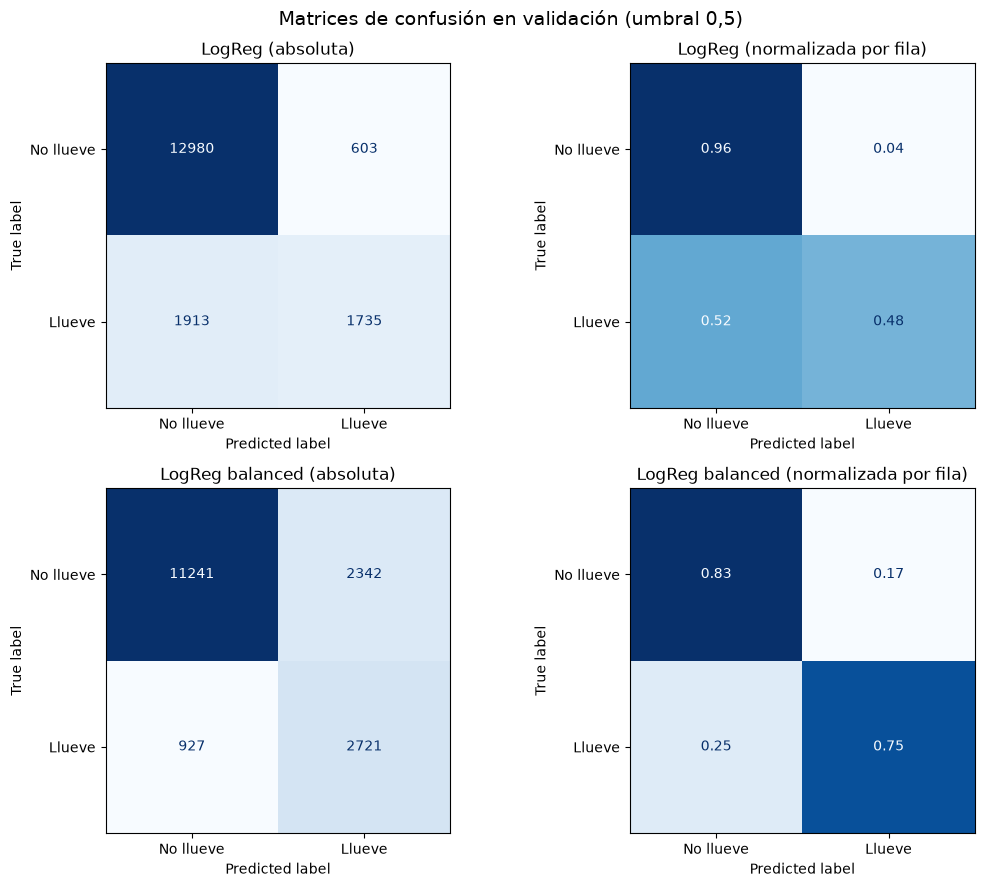

In [29]:
def graficar_confusiones(predicciones, y_true, titulo):
    fig, axes = plt.subplots(len(predicciones), 2, figsize=(11, 4.5 * len(predicciones)), squeeze=False)
    for fila, (nombre, pred) in enumerate(predicciones.items()):
        ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["No llueve", "Llueve"],
                                                cmap="Blues", ax=axes[fila, 0], colorbar=False)
        ConfusionMatrixDisplay.from_predictions(y_true, pred, display_labels=["No llueve", "Llueve"],
                                                normalize="true", values_format=".2f",
                                                cmap="Blues", ax=axes[fila, 1], colorbar=False)
        axes[fila, 0].set_title(f"{nombre} (absoluta)")
        axes[fila, 1].set_title(f"{nombre} (normalizada por fila)")
    plt.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    plt.show()


graficar_confusiones({nombre: modelo.predict(X_val) for nombre, modelo in MODELOS_LOGREG.items()},
                     y_val, "Matrices de confusión en validación (umbral 0,5)")

- **LogReg sin pesos:** con el umbral 0,5 acierta el 96 % de los días sin lluvia, pero
  detecta solo el 48 % de los días con lluvia. Más de la mitad de los días de lluvia
  terminan como **falsos negativos**. Es el sesgo esperado por el desbalance: ante la
  duda, el modelo predice la clase mayoritaria.
- **LogReg balanced:** el recall de la clase positiva sube al 75 %, a cambio de que el
  acierto en los días secos baje del 96 % al 83 %. Los falsos negativos se reducen a la
  mitad, pero aumentan los **falsos positivos**: la precision cae de 0,74 a 0,54, es decir
  que casi una de cada dos alarmas de lluvia es falsa.

Con la métrica elegida, la versión con pesos es mejor en validación (F1 de 0,625 contra
0,580). La accuracy dice lo contrario (0,854 contra 0,810), porque premia acertar los
días secos, que son la mayoría.

## 2.3 Curvas ROC

Cada punto de la curva ROC corresponde a un umbral distinto: el eje x es la tasa de falsos
positivos (FPR) y el eje y la tasa de verdaderos positivos (TPR, que es el recall). La
diagonal corresponde a un clasificador al azar.

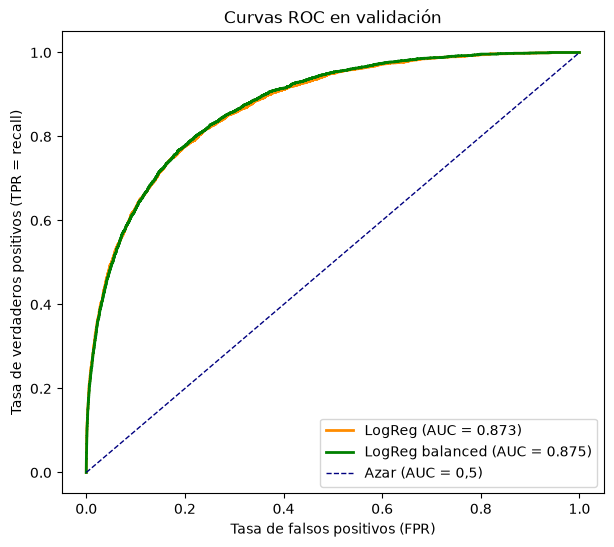

In [30]:
plt.figure(figsize=(7, 6))
for (nombre, modelo), color in zip(MODELOS_LOGREG.items(), ["darkorange", "green"]):
    proba = modelo.predict_proba(X_val)[:, 1]
    fpr, tpr, _ = roc_curve(y_val, proba)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_val, proba):.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Azar (AUC = 0,5)")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR = recall)")
plt.title("Curvas ROC en validación")
plt.legend(loc="lower right")
plt.show()

Las dos curvas prácticamente se superponen (AUC de 0,873 y 0,875). `class_weight`
desplaza las probabilidades hacia arriba, pero casi no cambia el **orden** de los días
según su probabilidad, que es lo que mide la curva ROC. Los dos modelos discriminan igual
de bien; lo que cambia es dónde cae el umbral de 0,5 sobre la curva.

Un AUC de 0,87 significa que, si se toman al azar un día previo a una lluvia y un día
previo a un día seco, el modelo le asigna mayor probabilidad de lluvia al primero el 87 %
de las veces. Está lejos del 0,5 del azar y del 1 de un modelo perfecto.

## 2.4 Elección del umbral

El umbral 0,5 es el valor por defecto de `predict`, no una obligación. Para ver cómo
cambia el comportamiento del modelo se recorren umbrales entre 0,05 y 0,95 sobre el
conjunto de validación con el modelo sin pesos, y se calculan precision, recall, F1 y
balanced accuracy para cada uno.

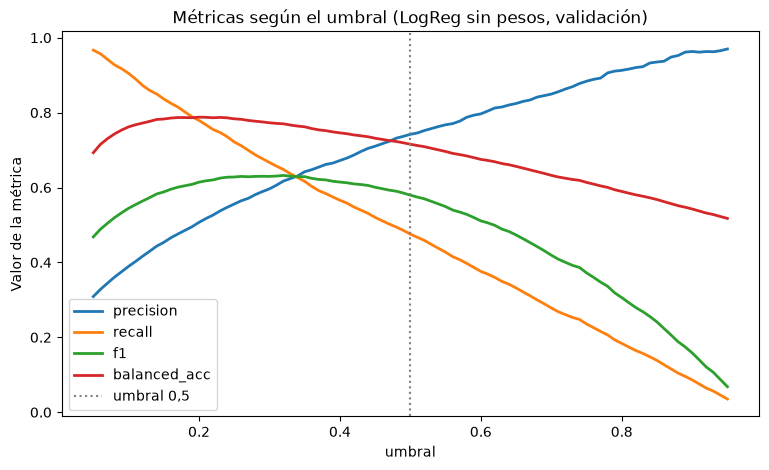

,precision,recall,f1,balanced_acc
umbral,,,,
0.1,0.389,0.905,0.545,0.762
0.2,0.507,0.779,0.614,0.788
0.3,0.596,0.667,0.630,0.773
0.4,0.672,0.566,0.615,0.746
0.5,0.742,0.476,0.580,0.716
0.6,0.797,0.376,0.511,0.675
0.7,0.849,0.279,0.419,0.633


In [31]:
proba_val = logreg.predict_proba(X_val)[:, 1]
umbrales = np.round(np.arange(0.05, 0.96, 0.01), 2)
barrido = pd.DataFrame([
    {
        "umbral": u,
        "precision": precision_score(y_val, proba_val >= u, zero_division=0),
        "recall": recall_score(y_val, proba_val >= u),
        "f1": f1_score(y_val, proba_val >= u),
        "balanced_acc": balanced_accuracy_score(y_val, proba_val >= u),
    }
    for u in umbrales
])

ax = barrido.plot(x="umbral", y=["precision", "recall", "f1", "balanced_acc"], figsize=(9, 5), lw=2)
ax.axvline(0.5, color="gray", linestyle=":", label="umbral 0,5")
ax.set_ylabel("Valor de la métrica")
ax.set_title("Métricas según el umbral (LogReg sin pesos, validación)")
ax.legend()
plt.show()

display(barrido[barrido["umbral"].isin([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7])].set_index("umbral").round(3))

Se comparan dos criterios para elegir el umbral:

- **Índice de Youden:** el umbral que maximiza $J = TPR - FPR$, es decir el punto de la
  curva ROC más alejado de la diagonal. Da el mismo peso al recall de ambas clases.
- **Máximo F1:** el umbral que maximiza el F1 de la clase positiva, coherente con la
  métrica principal elegida en 2.1.

Los dos se calculan **sobre validación**, nunca sobre prueba: elegir el umbral también es
ajustar el modelo.

Umbral Youden : 0.206
Umbral max F1 : 0.318


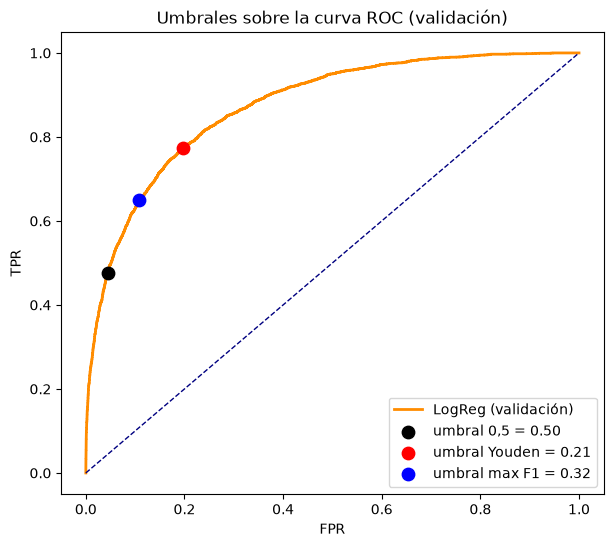

In [32]:
fpr_v, tpr_v, umbrales_roc = roc_curve(y_val, proba_val)
umbral_youden = umbrales_roc[np.argmax(tpr_v - fpr_v)]

prec_v, rec_v, umbrales_pr = precision_recall_curve(y_val, proba_val)
f1_v = 2 * prec_v[:-1] * rec_v[:-1] / (prec_v[:-1] + rec_v[:-1] + 1e-12)
umbral_f1 = umbrales_pr[np.argmax(f1_v)]

print(f"Umbral Youden : {umbral_youden:.3f}")
print(f"Umbral max F1 : {umbral_f1:.3f}")

plt.figure(figsize=(7, 6))
plt.plot(fpr_v, tpr_v, color="darkorange", lw=2, label="LogReg (validación)")
for umbral, color, etiqueta in [(0.5, "black", "0,5"), (umbral_youden, "red", "Youden"), (umbral_f1, "blue", "max F1")]:
    i = np.argmin(np.abs(umbrales_roc - umbral))
    plt.scatter(fpr_v[i], tpr_v[i], color=color, s=80, zorder=3, label=f"umbral {etiqueta} = {umbral:.2f}")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--")
plt.xlabel("FPR")
plt.ylabel("TPR")
plt.title("Umbrales sobre la curva ROC (validación)")
plt.legend(loc="lower right")
plt.show()

Con los umbrales fijados, se arma la tabla de **validación** de todas las variantes de
regresión logística. La variante con mayor F1 en validación es la que se elige.

In [33]:
VARIANTES = {
    "LogReg (0.50)": (logreg, 0.5),
    "LogReg balanced (0.50)": (logreg_bal, 0.5),
    f"LogReg Youden ({umbral_youden:.2f})": (logreg, umbral_youden),
    f"LogReg max F1 ({umbral_f1:.2f})": (logreg, umbral_f1),
}

tabla_val = pd.DataFrame([
    evaluar(nombre, "val", y_val, (modelo.predict_proba(X_val)[:, 1] >= umbral).astype(int),
            modelo.predict_proba(X_val)[:, 1])
    for nombre, (modelo, umbral) in VARIANTES.items()
]).drop(columns="conjunto").set_index("modelo").sort_values("f1", ascending=False)
display(tabla_val.round(3))

VARIANTE_ELEGIDA = tabla_val.index[0]
print(f"Variante elegida en validación: {VARIANTE_ELEGIDA}")

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
modelo,,,,,,,
LogReg max F1 (0.32),0.840,0.771,0.616,0.650,0.633,0.873,0.695
LogReg balanced (0.50),0.810,0.787,0.537,0.746,0.625,0.875,0.692
LogReg Youden (0.21),0.797,0.788,0.514,0.773,0.617,0.873,0.695
LogReg (0.50),0.854,0.716,0.742,0.476,0.580,0.873,0.695


Variante elegida en validación: LogReg max F1 (0.32)


- El barrido muestra el compromiso entre las métricas: al bajar el umbral sube el recall y
  baja la precision. El F1 forma una meseta entre 0,25 y 0,35, y en 0,5 ya cayó a 0,58.
  **0,5 no es el mejor umbral** para este problema: con solo un 22 % de días de lluvia,
  el modelo rara vez le asigna a la lluvia una probabilidad alta, y exigir más del 50 % deja
  pasar muchos días de lluvia.
- **Youden (0,21)** maximiza la balanced accuracy (0,788) y logra un recall del 77 %, con
  una precision de 0,51.
- **Máximo F1 (0,32)** logra el F1 más alto en validación (0,633), con un recall del 65 % y
  una precision de 0,62.
- **Variante elegida: regresión logística sin pesos con umbral 0,32**, por tener el mayor F1
  en validación. Mover el umbral y entrenar con `class_weight` atacan el mismo problema.
  En validación el umbral rinde apenas más (0,633 contra 0,625); la diferencia es chica,
  pero el umbral tiene una ventaja práctica: se puede ajustar sin reentrenar el modelo.
- Si quien usa el pronóstico considerara los falsos negativos mucho más caros que las
  falsas alarmas, el barrido permite elegir un umbral menor sabiendo cuánto se pierde: con
  0,2 el recall sube al 78 % y la precision baja a 0,51.

## 2.5 Evaluación final en el conjunto de prueba

Con las decisiones ya tomadas en validación, se evalúan todas las variantes en el
conjunto de prueba (2016–2017). Se muestran todas para cumplir con la consigna de
reportar cada modelo, pero **la elección no se modifica** según estos resultados.

In [34]:
for nombre, (modelo, umbral) in VARIANTES.items():
    proba = modelo.predict_proba(X_test)[:, 1]
    resultados.append(evaluar(nombre, "test", y_test, (proba >= umbral).astype(int), proba))

tabla_test_logreg = pd.DataFrame(resultados).query("conjunto == 'test'").drop(columns="conjunto").set_index("modelo")
display(tabla_test_logreg.round(3))

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
modelo,,,,,,,
LogReg (0.50),0.842,0.722,0.723,0.501,0.592,0.861,0.692
LogReg balanced (0.50),0.787,0.782,0.524,0.772,0.624,0.863,0.688
LogReg Youden (0.21),0.766,0.778,0.493,0.801,0.611,0.861,0.692
LogReg max F1 (0.32),0.823,0.772,0.601,0.678,0.637,0.861,0.692


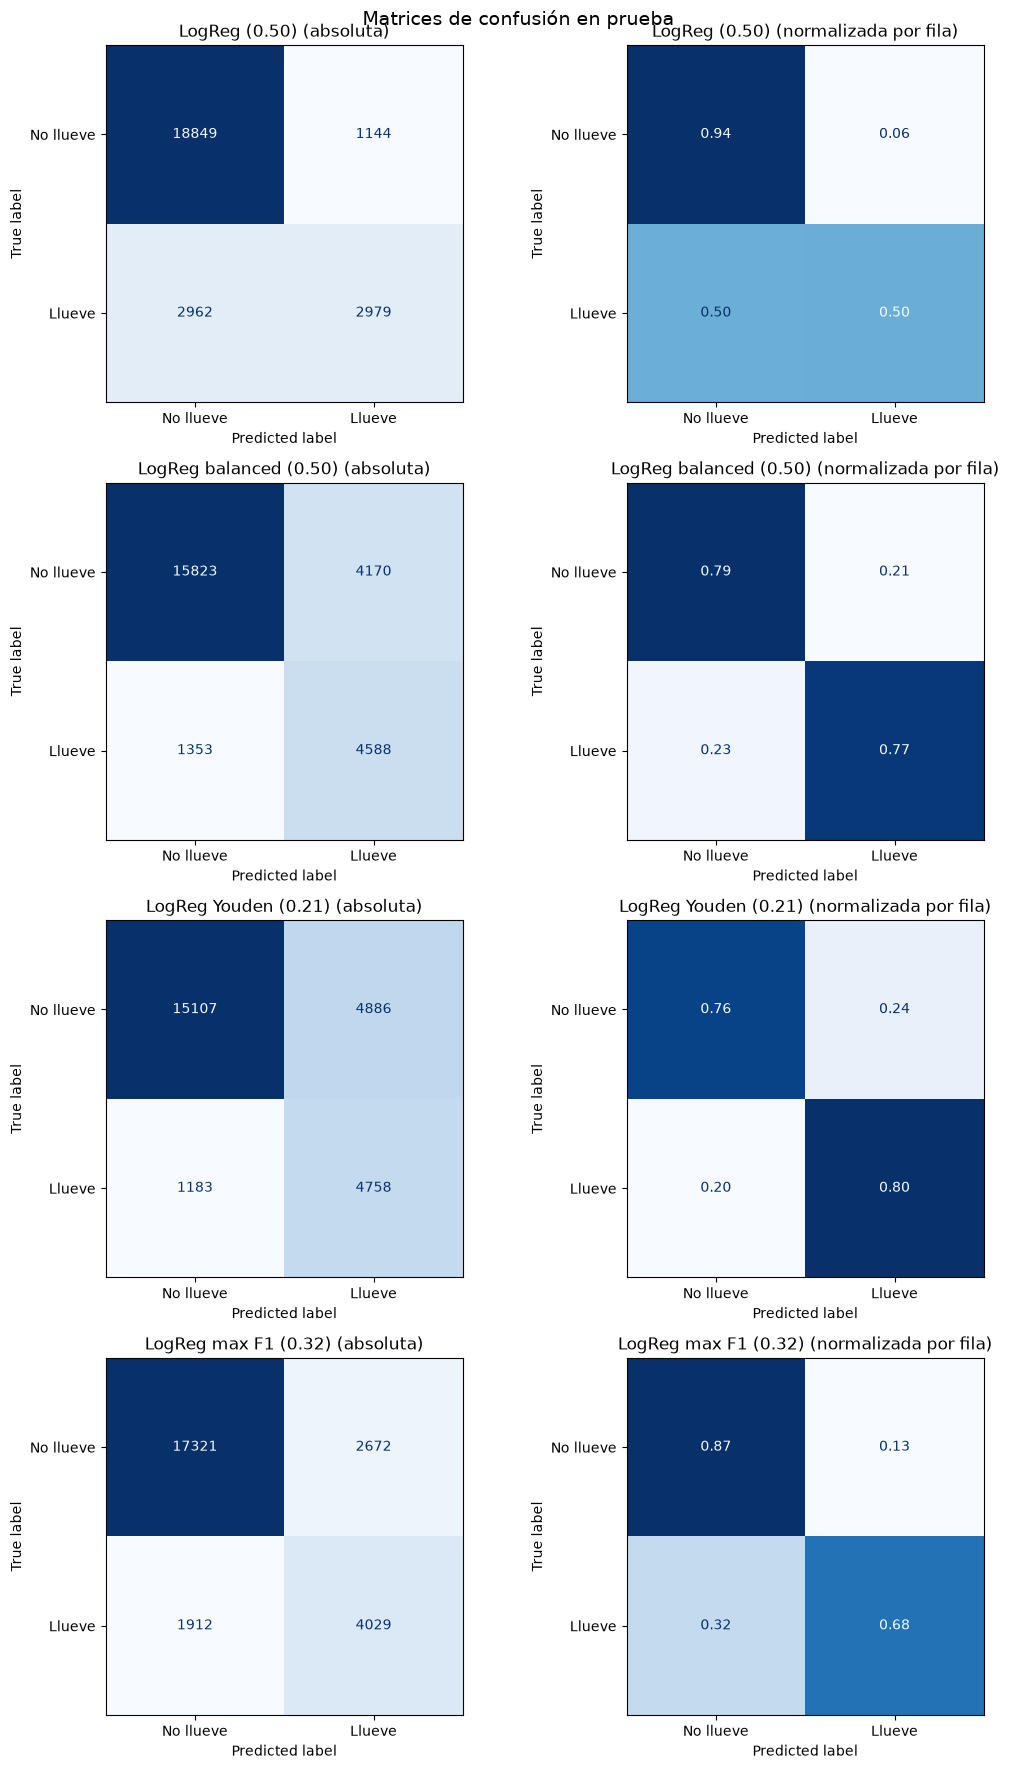

In [35]:
graficar_confusiones(
    {nombre: (modelo.predict_proba(X_test)[:, 1] >= umbral).astype(int) for nombre, (modelo, umbral) in VARIANTES.items()},
    y_test, "Matrices de confusión en prueba",
)

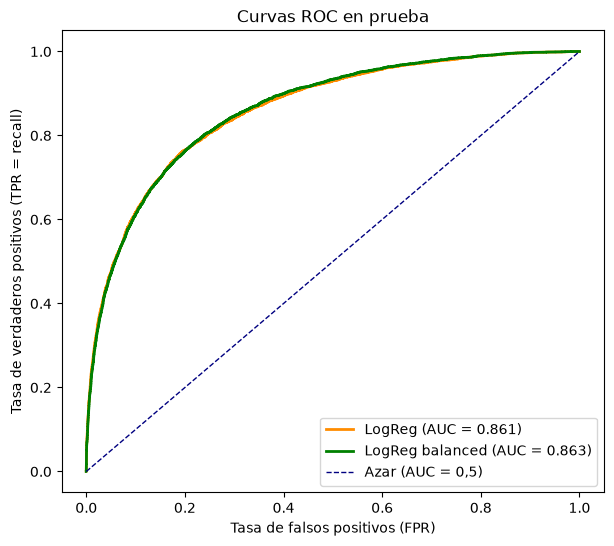

In [36]:
plt.figure(figsize=(7, 6))
for (nombre, modelo), color in zip(MODELOS_LOGREG.items(), ["darkorange", "green"]):
    proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, color=color, lw=2, label=f"{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})")
plt.plot([0, 1], [0, 1], color="navy", lw=1, linestyle="--", label="Azar (AUC = 0,5)")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR = recall)")
plt.title("Curvas ROC en prueba")
plt.legend(loc="lower right")
plt.show()

- La variante elegida (umbral 0,32) obtiene en prueba un F1 de **0,637**, con un recall del
  68 % y una precision de 0,60. Detecta dos de cada tres días de lluvia y da falsa alarma
  en el 13 % de los días secos. El F1 es casi igual al de validación (0,633): el umbral
  elegido en 2015 se sostiene en 2016–2017.
- El orden de las variantes según el F1 es el mismo que en validación. Las decisiones
  tomadas en validación se trasladan bien a datos nuevos.
- La variante con umbral 0,5 tiene la mayor accuracy (0,842) y el peor F1 (0,592). Es un
  ejemplo concreto de por qué la accuracy no sirve para elegir el modelo en este problema.
- La ROC-AUC en prueba (0,861) es algo menor que en validación (0,873). La ROC-AUC no
  depende de la proporción de lluvia, así que la diferencia indica que en 2016–2017 el
  modelo ordena los días un poco peor que en 2015. Es una pérdida chica y esperable cuando
  los datos se alejan en el tiempo del período de entrenamiento.
- ROC-AUC y PR-AUC son iguales para todas las variantes que comparten el modelo sin pesos,
  porque se calculan sobre las probabilidades y no dependen del umbral.

## 2.6 ¿Conseguimos un buen fitting?

Para diagnosticar el ajuste se compara el rendimiento en entrenamiento y en validación con
todas las métricas: ROC-AUC y PR-AUC, que no dependen del umbral, y F1, precision y recall
con el umbral 0,5 y con el umbral elegido. Una brecha grande indicaría sobreajuste; valores
bajos en ambos conjuntos, subajuste.

In [37]:
proba_train = logreg.predict_proba(X_train)[:, 1]
filas_umbral = [
    evaluar(f"LogReg max F1 ({umbral_f1:.2f})", conjunto, y, (proba >= umbral_f1).astype(int), proba)
    for conjunto, y, proba in [("train", y_train, proba_train), ("val", y_val, proba_val)]
]
comparacion_fit = pd.concat([
    pd.DataFrame(resultados).query("conjunto in ['train', 'val']"),
    pd.DataFrame(filas_umbral),
]).set_index(["modelo", "conjunto"])
display(comparacion_fit[["f1", "precision", "recall", "roc_auc", "pr_auc"]].round(3))

brecha = comparacion_fit.xs("train", level="conjunto") - comparacion_fit.xs("val", level="conjunto")
print("Diferencia entrenamiento - validación:")
display(brecha[["f1", "precision", "recall", "roc_auc", "pr_auc"]].round(3))

f1  precision  recall  roc_auc  pr_auc
modelo               conjunto                                           
LogReg               train     0.612      0.732   0.526    0.876   0.713
                     val       0.580      0.742   0.476    0.873   0.695
LogReg balanced      train     0.634      0.533   0.783    0.876   0.710
                     val       0.625      0.537   0.746    0.875   0.692
LogReg max F1 (0.32) train     0.648      0.610   0.691    0.876   0.713
                     val       0.633      0.616   0.650    0.873   0.695

Diferencia entrenamiento - validación:


,f1,precision,recall,roc_auc,pr_auc
modelo,,,,,
LogReg,0.032,-0.010,0.050,0.003,0.019
LogReg balanced,0.010,-0.004,0.037,0.002,0.018
LogReg max F1 (0.32),0.015,-0.006,0.041,0.003,0.019


La validación es un año posterior al entrenamiento, así que una diferencia entre ambos
conjuntos puede deberse a sobreajuste o a que 2015 tuvo condiciones distintas a las de los
años anteriores. Para separar en parte los dos efectos, se calcula el rendimiento del mismo
modelo en cada año completo del entrenamiento (2009 a 2014; 2007 y 2008 tienen pocos
registros). Si la validación queda dentro de la variación entre años del entrenamiento, la
diferencia no se puede atribuir al sobreajuste. También se compara la probabilidad media
que predice el modelo con la proporción real de lluvia.

In [38]:
def metricas_periodo(subconjunto):
    proba = logreg.predict_proba(subconjunto[COLS_ENTRADA])[:, 1]
    y = subconjunto[TARGET]
    return {
        "filas": len(subconjunto),
        "roc_auc": roc_auc_score(y, proba),
        "precision_0.50": precision_score(y, proba >= 0.5),
        "recall_0.50": recall_score(y, proba >= 0.5),
        "prob_media": proba.mean(),
        "tasa_real": y.mean(),
    }


periodos = {f"train {anio}": train[train["Date"].dt.year == anio] for anio in range(2009, 2015)}
periodos["validación 2015"] = val
display(pd.DataFrame({nombre: metricas_periodo(s) for nombre, s in periodos.items()}).T.round(3))

,filas,roc_auc,precision_0.50,recall_0.50,prob_media,tasa_real
train 2009,16595.0,0.879,0.722,0.535,0.222,0.217
train 2010,16419.0,0.877,0.737,0.541,0.242,0.243
train 2011,15126.0,0.870,0.760,0.530,0.241,0.247
train 2012,15044.0,0.880,0.741,0.502,0.217,0.225
train 2013,16097.0,0.880,0.734,0.543,0.220,0.215
train 2014,17400.0,0.872,0.705,0.505,0.209,0.204
validación 2015,17231.0,0.873,0.742,0.476,0.203,0.212


**Comparación entrenamiento – validación.** Las métricas que no dependen del umbral casi
no cambian: la ROC-AUC baja 0,003 (0,876 contra 0,873) y la PR-AUC alrededor de 0,02. Con
umbral fijo la situación es más matizada. La precision se mantiene o incluso sube en
validación (0,732 contra 0,742 con el umbral 0,5), pero el recall baja entre 4 y 5 puntos
en las tres variantes (0,526 contra 0,476 sin pesos y umbral 0,5; 0,691 contra 0,650 con
el umbral 0,32; 0,783 contra 0,746 con pesos). Toda la brecha del F1 (entre 0,01 y 0,03)
viene de esa caída del recall.

**Comparación por año.** En los años completos del entrenamiento la ROC-AUC varía entre
0,870 y 0,880, y la de validación (0,873) cae dentro de ese rango: el modelo distingue los
días de lluvia en 2015 tan bien como en los años con los que se entrenó. El recall con
umbral 0,5, en cambio, varía entre 0,50 y 0,54 en el entrenamiento, y en validación queda
algo por debajo (0,48). Además, en 2015 la probabilidad media predicha (0,203) queda por
debajo de la proporción real de lluvia (0,212), mientras que en el entrenamiento coinciden
(0,225). Con probabilidades un poco más bajas, menos días superan el umbral y el recall
baja.

**Conclusión:**

- **No hay evidencia de un sobreajuste relevante.** La capacidad de discriminación es la
  misma dentro y fuera del entrenamiento, y la precision no se deteriora. Es lo esperable:
  con unas 99 mil filas y 97 columnas, un modelo lineal regularizado tiene pocos
  parámetros en relación con la cantidad de datos.
- **No se puede afirmar que el sobreajuste sea nulo.** La caída del recall supera
  ligeramente la variación entre años del entrenamiento. Puede deberse a un sobreajuste
  leve o a condiciones particulares de 2015, en el que el modelo subestima un poco la
  probabilidad de lluvia. Con una sola partición temporal de validación no se pueden
  separar ambas causas. La validación cruzada temporal del ítem 4 va a permitir medir esta
  variación con más folds.
- **Hay cierto subajuste.** El modelo tampoco llega a valores altos en el entrenamiento
  (ROC-AUC de 0,876 y F1 entre 0,61 y 0,65): el límite parece estar en el modelo y no en
  la cantidad de datos. La regresión logística solo puede trazar una frontera lineal (un
  hiperplano), y no captura interacciones como la de humedad alta con presión en descenso,
  salvo que se construyan a mano.

Las mejoras posibles van por el lado de ajustar la regularización `C` (ítem 4) y de darle
más capacidad al modelo con una red neuronal, que puede capturar relaciones no lineales
(ítem 7).

# Ítem 3 – Modelos base

Un modelo base es un modelo simple, que no aprende casi nada. Sirve como punto de
partida: cualquier modelo que se desarrolle tiene que superarlo, y por un margen que
valga la pena. Si un modelo base le ganara a la regresión logística, sería señal de un
error. Se implementan los tres tipos de modelo base para clasificación que se vieron en
clase:

- **Por mayoría** (`DummyClassifier(strategy="most_frequent")`): predice siempre
  "no llueve". Es el más útil en un problema desbalanceado, porque muestra cuánta accuracy
  se obtiene "gratis".
- **Aleatorio estratificado** (`DummyClassifier(strategy="stratified")`): predice al azar
  respetando la proporción de clases del entrenamiento (22 % de lluvia).
- **Persistencia** (criterio ingenuo): "mañana llueve si hoy llovió". Es el equivalente,
  para series de tiempo, de predecir el último valor observado. Usa una sola variable y
  ningún parámetro. Si `RainToday` falta, se asume que hoy no llovió, que es la clase más
  frecuente.

La consigna pide repetir los pasos del ítem anterior que sean necesarios. Se repiten las
métricas, las matrices de confusión y las curvas ROC, sobre los **mismos** conjuntos de
validación y prueba y con la misma función `evaluar`, para que la comparación sea justa.
No tiene sentido elegir un umbral ni analizar el fitting de estos modelos: los dos
`DummyClassifier` no usan las variables de entrada, y la persistencia no tiene
probabilidades ni parámetros que ajustar.

In [39]:
dummy_mayoria = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_estratificado = DummyClassifier(strategy="stratified", random_state=RANDOM_STATE).fit(X_train, y_train)


def predecir_persistencia(X):
    return X["RainToday"].map({"No": 0, "Yes": 1}).fillna(0).astype(int)


BASES = {"Base: mayoría": dummy_mayoria, "Base: aleatorio estratificado": dummy_estratificado}
for conjunto, X, y in [("val", X_val, y_val), ("test", X_test, y_test)]:
    for nombre, modelo in BASES.items():
        resultados.append(evaluar(nombre, conjunto, y, modelo.predict(X), modelo.predict_proba(X)[:, 1]))
    resultados.append(evaluar("Base: persistencia", conjunto, y, predecir_persistencia(X)))

tabla_resultados = pd.DataFrame(resultados)
tabla_bases = tabla_resultados[tabla_resultados["modelo"].str.startswith("Base")].set_index(["modelo", "conjunto"])
display(tabla_bases.round(3))

,,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
modelo,conjunto,,,,,,,
Base: mayoría,val,0.788,0.500,0.000,0.000,0.000,0.500,0.212
Base: aleatorio estratificado,val,0.659,0.499,0.210,0.221,0.215,0.499,0.211
Base: persistencia,val,0.772,0.656,0.461,0.455,0.458,NaN,NaN
Base: mayoría,test,0.771,0.500,0.000,0.000,0.000,0.500,0.229
Base: aleatorio estratificado,test,0.652,0.505,0.237,0.232,0.235,0.505,0.231
Base: persistencia,test,0.748,0.641,0.450,0.444,0.447,NaN,NaN


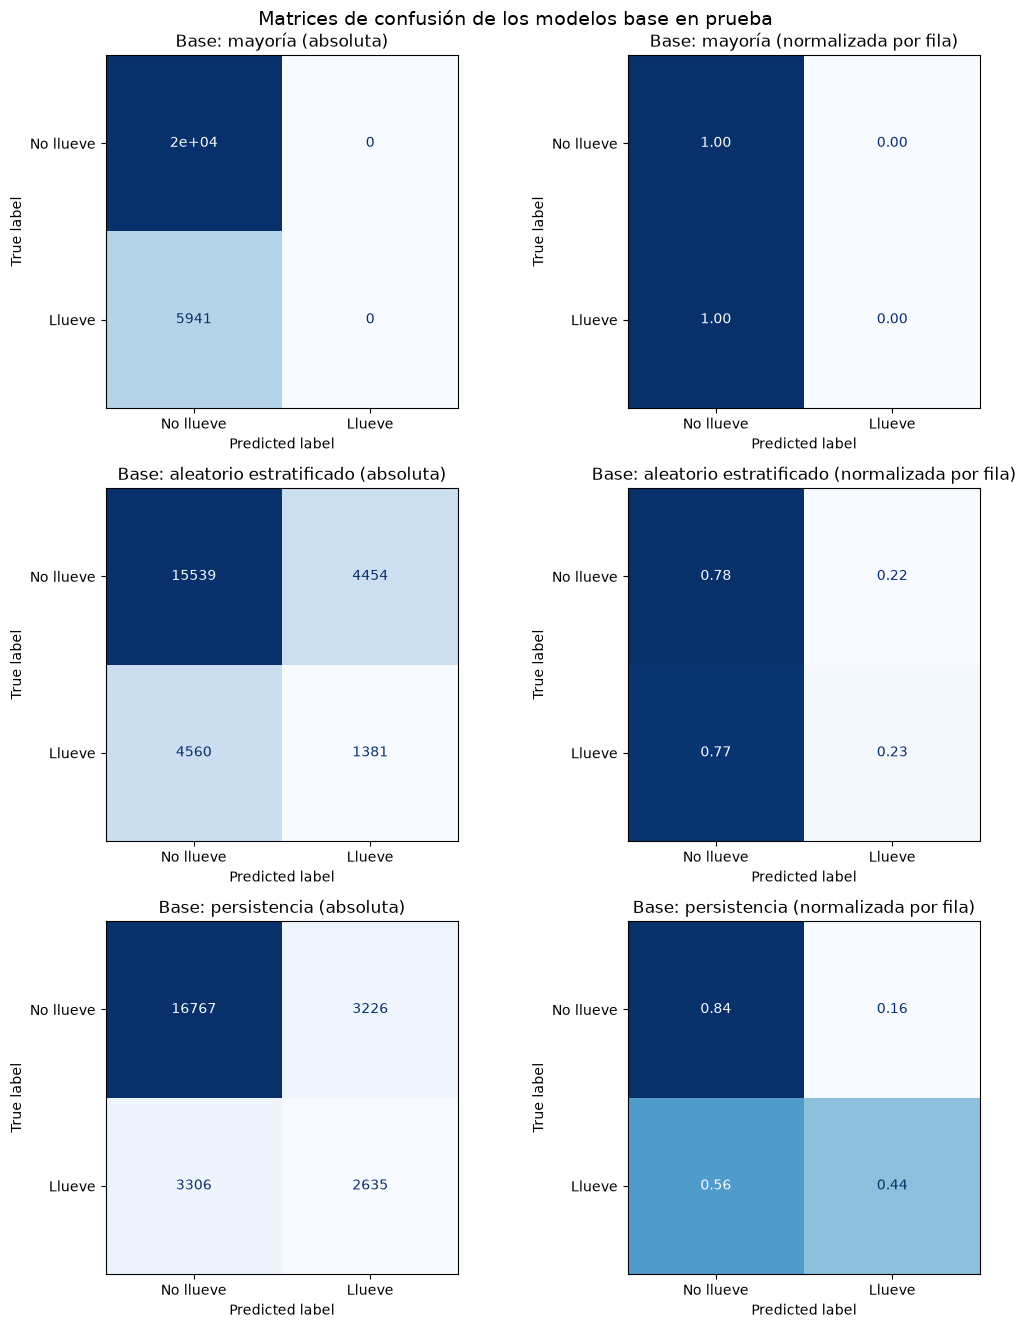

In [40]:
graficar_confusiones(
    {nombre: modelo.predict(X_test) for nombre, modelo in BASES.items()} | {"Base: persistencia": predecir_persistencia(X_test)},
    y_test, "Matrices de confusión de los modelos base en prueba",
)

En la curva ROC, los dos `DummyClassifier` dan probabilidades que no dependen de las
variables, así que su curva coincide con la diagonal del azar. La persistencia no tiene
probabilidades: es un único punto (FPR, TPR). Se grafican junto con la regresión
logística.

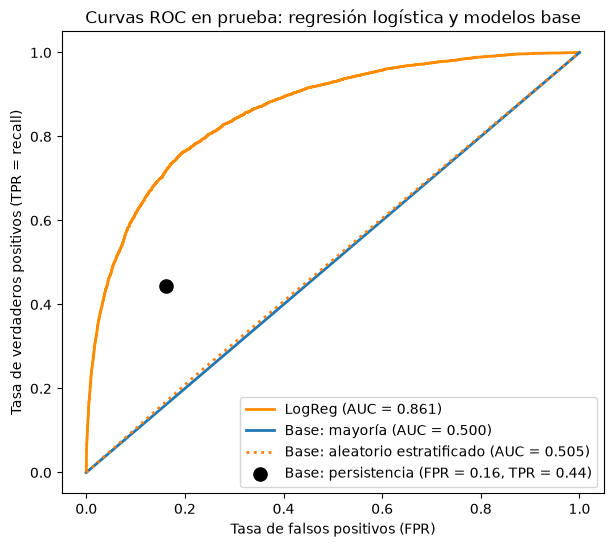

In [41]:
plt.figure(figsize=(7, 6))
proba_logreg_test = logreg.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, proba_logreg_test)
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"LogReg (AUC = {roc_auc_score(y_test, proba_logreg_test):.3f})")
for (nombre, modelo), estilo in zip(BASES.items(), ["-", ":"]):
    proba = modelo.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, lw=2, linestyle=estilo, label=f"{nombre} (AUC = {roc_auc_score(y_test, proba):.3f})")

pred_persistencia = predecir_persistencia(X_test)
fpr_p = ((pred_persistencia == 1) & (y_test == 0)).sum() / (y_test == 0).sum()
tpr_p = ((pred_persistencia == 1) & (y_test == 1)).sum() / (y_test == 1).sum()
plt.scatter(fpr_p, tpr_p, color="black", s=90, zorder=3, label=f"Base: persistencia (FPR = {fpr_p:.2f}, TPR = {tpr_p:.2f})")
plt.xlabel("Tasa de falsos positivos (FPR)")
plt.ylabel("Tasa de verdaderos positivos (TPR = recall)")
plt.title("Curvas ROC en prueba: regresión logística y modelos base")
plt.legend(loc="lower right")
plt.show()

Por último, la comparación de todos los modelos sobre el conjunto de prueba, ordenados por
la métrica principal (F1 de la clase positiva).

,accuracy,balanced_acc,precision,recall,f1,roc_auc,pr_auc
modelo,,,,,,,
LogReg max F1 (0.32),0.823,0.772,0.601,0.678,0.637,0.861,0.692
LogReg balanced (0.50),0.787,0.782,0.524,0.772,0.624,0.863,0.688
LogReg Youden (0.21),0.766,0.778,0.493,0.801,0.611,0.861,0.692
LogReg (0.50),0.842,0.722,0.723,0.501,0.592,0.861,0.692
Base: persistencia,0.748,0.641,0.450,0.444,0.447,NaN,NaN
Base: aleatorio estratificado,0.652,0.505,0.237,0.232,0.235,0.505,0.231
Base: mayoría,0.771,0.500,0.000,0.000,0.000,0.500,0.229


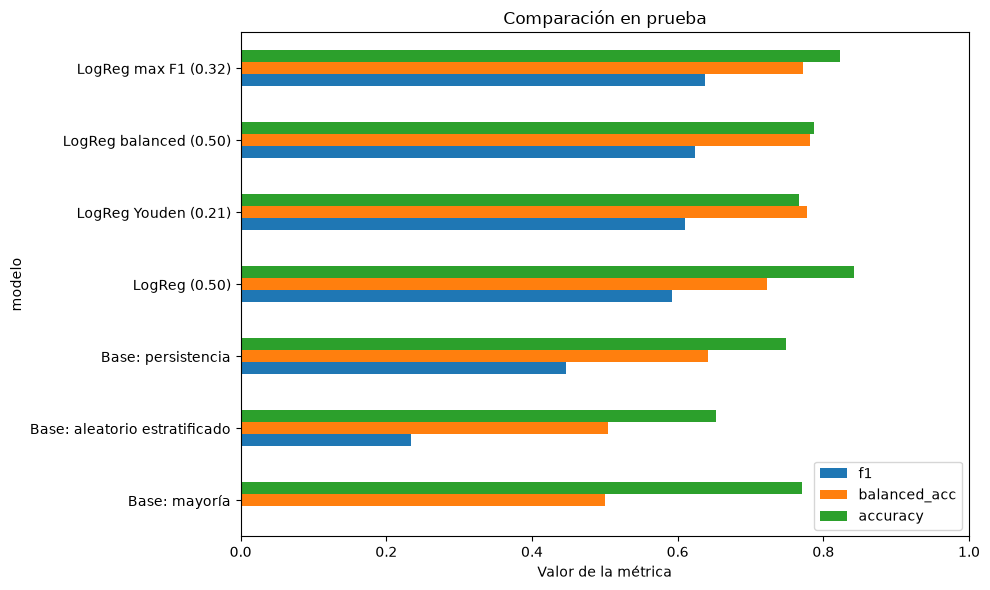

In [42]:
tabla_test = (pd.DataFrame(resultados).query("conjunto == 'test'").drop(columns="conjunto")
              .set_index("modelo").sort_values("f1", ascending=False))
display(tabla_test.round(3))

tabla_test[["f1", "balanced_acc", "accuracy"]].iloc[::-1].plot.barh(figsize=(10, 6))
plt.title("Comparación en prueba")
plt.xlabel("Valor de la métrica")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

- **Base por mayoría:** obtiene un 77,1 % de accuracy en prueba, 7 puntos menos que la
  regresión logística con umbral 0,5, sin haber aprendido nada. Pero su recall, su
  precision y su F1 valen 0, y su balanced accuracy y su ROC-AUC valen 0,5. Es la prueba
  práctica de por qué la accuracy no sirve como métrica principal en este dataset.
- **Base aleatoria estratificada:** su F1 (0,235) queda cerca de la proporción de días de
  lluvia, que es lo que se espera de predecir al azar, y su ROC-AUC es 0,5. Cualquier
  modelo que no supere ese valor no aprendió nada útil.
- **Base por persistencia:** con una sola variable alcanza un F1 de 0,447 y detecta el 44 %
  de los días de lluvia, con falsas alarmas en el 16 % de los días secos. Es el piso más
  exigente de los tres. En la curva ROC su punto queda claramente por debajo de la curva de
  la regresión logística: para la misma tasa de falsas alarmas, la regresión logística
  detecta muchos más días de lluvia.
- **La regresión logística supera a los tres con margen.** La variante elegida (umbral
  0,32) llega a un F1 de 0,637 contra 0,447 de la persistencia, y a una balanced accuracy
  de 0,772 contra 0,641. En validación la conclusión es la misma (F1 de 0,633 contra
  0,458). El modelo aporta información real, más allá de "si hoy llovió, mañana también".

Para comparar todos los modelos en el ítem 8 se mantiene la métrica definida en la
sección 2.1: el F1 de la clase positiva.